# Colorectal Histology Classification with Deep Learning

**A reproducible, explainable portfolio experiment — official PathMNIST, nine tissue classes.**

Upload this notebook into Google Colab, select **Runtime → Change runtime type → GPU**, then run Cells **1–10 in order**. Everything needed is embedded below; no repository or project ZIP upload is required. The default uses 20,000 official training images, all validation images and all test images. Choose `full` in Cell 3 before starting if you want the entire training split.

**Execution disclosure:** no PathMNIST models were trained during notebook delivery. A separate local CPU synthetic software test verifies training, checkpoint reload and report generation; it does not measure histology performance. Real model tables and plots below appear only after you execute the cells. No results are prefilled. This is not a clinically validated diagnostic tool.

**Question:** under a bounded compute budget, how do a small CNN and pretrained ResNet18 differ in patch classification and error patterns? This compares full pipelines; it does not isolate the effect of pretraining.

## Biology in plain English
Histology studies thin tissue slices under a microscope. H&E combines hematoxylin, which emphasizes blue-purple nuclear material, and eosin, which emphasizes pink/red cell material and supporting tissue. A patch is a small image region, not a whole slide or a patient. Lymphocytes are immune cells; classifying a lymphocyte-rich patch does not measure immune function.

| ID | Official tissue class | Plain explanation |
|---|---|---|
| 0 | adipose | Fat |
| 1 | background | Non-tissue area |
| 2 | debris | Tissue/cellular remnants |
| 3 | lymphocytes | Immune cells |
| 4 | mucus | Secreted gel-like material |
| 5 | smooth muscle | Involuntary muscle |
| 6 | normal colon mucosa | Normal inner colon lining |
| 7 | cancer-associated stroma | Supporting tissue associated with tumor |
| 8 | colorectal adenocarcinoma epithelium | Gland-forming colorectal cancer epithelial tissue |

## Dataset provenance and boundaries
Official split sizes: **89,996 training / 10,004 validation / 7,180 test**. RGB images here are 28×28, derived from 224×224 source patches. MedMNIST uses NCT-CRC-HE-100K for train/validation and CRC-VAL-HE-7K for test. The original source archive reports separate patients between those source cohorts. We have **not independently audited patient IDs or verified patient-disjoint train/validation membership**. Official split membership is preserved; no reshuffling of combined splits occurs.

Data: CC BY 4.0. Attribute MedMNIST/Yang et al. and the original Kather et al. datasets, link the license and state modifications. MedMNIST code is Apache-2.0. The official archive is downloaded via `PathMNIST(..., download=True)`. Its bytes contain all splits, but test arrays are not analyzed until model selection is frozen. Sources and attribution appear at the end and in the embedded documentation.


## Cell 1 — Setup and hardware
Keep Colab's matched CUDA PyTorch/torchvision installation. Install missing project dependencies, then verify imports. CPU fallback is valid but slower. If you changed package versions in a previously used runtime and imports fail, start a fresh runtime rather than mixing torch/torchvision builds.


In [1]:
import sys, subprocess, importlib.metadata
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet',
    'medmnist==3.0.2', 'numpy>=1.26,<3', 'pandas>=2.1,<4',
    'scikit-learn>=1.4,<2', 'matplotlib>=3.8,<4', 'Pillow>=10,<13'])
import torch, torchvision, medmnist
print('Python:', sys.version)
print('torch:', torch.__version__, 'torchvision:', torchvision.__version__, 'MedMNIST:', medmnist.__version__)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE — CPU fallback; select a GPU runtime for practical training')


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
torch: 2.11.0+cu130 torchvision: 0.26.0+cu130 MedMNIST: 3.0.2
GPU: Tesla T4


## Cell 2 — Materialize the reusable code
This cell writes the exact packaged modules and explanatory documents into `/content/colorectal_histology` (or the current directory outside Colab). It does not fetch a repository. You can inspect the `.py` files in Colab's Files panel. The rest of the notebook uses these modules directly.


In [2]:
from pathlib import Path
import os, sys
PROJECT = Path('/content/colorectal_histology') if Path('/content').exists() else Path.cwd()/'colorectal_histology_colab'
PROJECT.mkdir(parents=True, exist_ok=True)
FILES = {'histology/__init__.py': '"""Reproducible, educational PathMNIST experiments."""\n__version__ = "1.0.0"\n', 'histology/core.py': '"""Training and reporting, independent of MedMNIST/torchvision for offline tests."""\nfrom __future__ import annotations\n\nimport hashlib\nimport importlib.metadata\nimport json\nimport os\nimport platform\nimport random\nimport time\nfrom pathlib import Path\n\nimport matplotlib\nmatplotlib.use("Agg")\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nimport torch\nfrom sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score\nfrom torch import nn\nfrom torch.utils.data import DataLoader\n\n\ndef save_json(path, value):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    path.write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")\n\n\ndef sha256(path):\n    digest = hashlib.sha256()\n    with open(path, "rb") as stream:\n        for chunk in iter(lambda: stream.read(1024 * 1024), b""):\n            digest.update(chunk)\n    return digest.hexdigest()\n\n\ndef seed_everything(seed=42):\n    # Set before the first CUDA operation. Cross-version bitwise identity is not promised.\n    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"\n    random.seed(seed)\n    np.random.seed(seed)\n    torch.manual_seed(seed)\n    if torch.cuda.is_available():\n        torch.cuda.manual_seed_all(seed)\n    torch.backends.cudnn.benchmark = False\n    torch.backends.cudnn.deterministic = True\n    torch.use_deterministic_algorithms(True, warn_only=True)\n\n\ndef seed_worker(worker_id):\n    worker_seed = torch.initial_seed() % 2**32\n    random.seed(worker_seed)\n    np.random.seed(worker_seed)\n\n\ndef make_loader(dataset, batch_size, training=False, seed=42, workers=0, device="cpu"):\n    return DataLoader(\n        dataset, batch_size=batch_size, shuffle=training,\n        num_workers=workers, worker_init_fn=seed_worker,\n        generator=torch.Generator().manual_seed(seed),\n        pin_memory=str(device).startswith("cuda"), drop_last=False,\n    )\n\n\ndef environment():\n    versions = {}\n    for name in ["torch", "torchvision", "medmnist", "numpy", "pandas", "scikit-learn", "matplotlib", "Pillow"]:\n        try:\n            versions[name] = importlib.metadata.version(name)\n        except importlib.metadata.PackageNotFoundError:\n            versions[name] = "NOT INSTALLED"\n    return {\n        "python": platform.python_version(), "platform": platform.platform(),\n        "versions": versions, "cuda_available": torch.cuda.is_available(),\n        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,\n        "torch_cuda_version": torch.version.cuda,\n        "determinism": "seeded; deterministic algorithms warn on unsupported operations; hardware/version differences remain",\n    }\n\n\nclass CompactCNN(nn.Module):\n    """Three 3x3 conv blocks: 3->32->64->128; global average pooling; nine logits."""\n    def __init__(self, classes=9):\n        super().__init__()\n        blocks = []\n        in_channels = 3\n        for channels in (32, 64, 128):\n            blocks.extend([nn.Conv2d(in_channels, channels, 3, padding=1, bias=False),\n                           nn.BatchNorm2d(channels), nn.ReLU(), nn.MaxPool2d(2)])\n            in_channels = channels\n        self.features = nn.Sequential(*blocks)\n        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),\n                                  nn.Dropout(0.2), nn.Linear(128, classes))\n\n    def forward(self, x):\n        return self.head(self.features(x))\n\n\ndef set_training_mode(model):\n    model.train()\n    # A frozen ResNet stem/layers 1-3 must also retain their pretrained BN statistics.\n    if getattr(model, "freeze_early_layers", False):\n        for name, child in model.named_children():\n            if name not in ("layer4", "fc"):\n                child.eval()\n\n\ndef pass_batches(model, loader, device, optimizer=None, scaler=None):\n    training = optimizer is not None\n    set_training_mode(model) if training else model.eval()\n    loss_function = nn.CrossEntropyLoss()\n    total_loss, total = 0.0, 0\n    truths, probabilities = [], []\n    amp = str(device).startswith("cuda")\n    with torch.set_grad_enabled(training):\n        for images, labels in loader:\n            images = images.to(device, non_blocking=amp)\n            labels = labels.reshape(-1).to(device=device, dtype=torch.long)\n            if training:\n                optimizer.zero_grad(set_to_none=True)\n            with torch.autocast(device_type=torch.device(device).type, enabled=amp):\n                logits = model(images)\n                loss = loss_function(logits, labels)\n            if not torch.isfinite(loss):\n                raise FloatingPointError("Non-finite loss; do not report this run as successful.")\n            if training:\n                scaler.scale(loss).backward()\n                scaler.unscale_(optimizer)\n                nn.utils.clip_grad_norm_(model.parameters(), 5.0)\n                scaler.step(optimizer)\n                scaler.update()\n            total_loss += float(loss.detach()) * labels.numel()\n            total += labels.numel()\n            truths.append(labels.detach().cpu().numpy())\n            probabilities.append(torch.softmax(logits.detach().float(), dim=1).cpu().numpy())\n    if total == 0:\n        raise ValueError("Empty data loader")\n    return total_loss / total, np.concatenate(truths), np.concatenate(probabilities)\n\n\ndef score_predictions(truth, probabilities, class_names):\n    truth = np.asarray(truth).reshape(-1)\n    probabilities = np.asarray(probabilities)\n    k = len(class_names)\n    if probabilities.shape != (len(truth), k):\n        raise ValueError("Expected N x number-of-classes probability matrix")\n    if not np.isfinite(probabilities).all() or (probabilities < 0).any():\n        raise ValueError("Invalid probabilities")\n    if not np.allclose(probabilities.sum(axis=1), 1, atol=1e-5):\n        raise ValueError("Probabilities must sum to one")\n    if not np.isin(truth, np.arange(k)).all():\n        raise ValueError("Labels outside class mapping")\n    predicted = probabilities.argmax(axis=1)\n    labels = list(range(k))\n    return {\n        "n_samples": len(truth),\n        "accuracy": float(accuracy_score(truth, predicted)),\n        "macro_f1": float(f1_score(truth, predicted, labels=labels, average="macro", zero_division=0)),\n        "per_class": classification_report(truth, predicted, labels=labels, target_names=class_names,\n                                            output_dict=True, zero_division=0),\n        "confusion_matrix": confusion_matrix(truth, predicted, labels=labels).tolist(),\n    }\n\n\ndef fit_model(model, train_loader, val_loader, class_names, output, device="cpu",\n              epochs=6, lr=1e-3, patience=2, metadata=None):\n    """Select the best completed epoch ONLY by validation macro-F1; ties keep earlier epoch."""\n    if epochs < 1 or patience < 1:\n        raise ValueError("epochs and patience must be positive")\n    output = Path(output)\n    output.mkdir(parents=True, exist_ok=True)\n    checkpoint = output / "best.pt"\n    if checkpoint.exists():\n        raise FileExistsError(f"Use a fresh run directory; refusing to overwrite {checkpoint}")\n    model.to(device)\n    optimizer = torch.optim.AdamW((p for p in model.parameters() if p.requires_grad), lr=lr, weight_decay=1e-4)\n    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)\n    scaler = torch.amp.GradScaler("cuda", enabled=str(device).startswith("cuda"))\n    best, stale, history = -1.0, 0, []\n    start = time.perf_counter()\n    for epoch in range(1, epochs + 1):\n        tick = time.perf_counter()\n        train_loss, train_y, train_p = pass_batches(model, train_loader, device, optimizer, scaler)\n        val_loss, val_y, val_p = pass_batches(model, val_loader, device)\n        val_metrics = score_predictions(val_y, val_p, class_names)\n        row = {\n            "epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,\n            "train_accuracy": float(accuracy_score(train_y, train_p.argmax(1))),\n            "val_accuracy": val_metrics["accuracy"], "val_macro_f1": val_metrics["macro_f1"],\n            "learning_rate": optimizer.param_groups[0]["lr"],\n            "epoch_seconds": time.perf_counter() - tick,\n        }\n        history.append(row)\n        pd.DataFrame(history).to_csv(output / "history.csv", index=False)\n        print(json.dumps(row), flush=True)\n        if val_metrics["macro_f1"] > best:\n            best, stale = val_metrics["macro_f1"], 0\n            torch.save({"model_state": model.state_dict(), "epoch": epoch,\n                        "val_macro_f1": best, "class_names": class_names,\n                        "metadata": metadata or {}}, checkpoint)\n        else:\n            stale += 1\n        scheduler.step()\n        if stale >= patience:\n            break\n    saved = torch.load(checkpoint, map_location=device, weights_only=True)\n    model.load_state_dict(saved["model_state"])\n    model.eval()\n    summary = {"best_epoch": saved["epoch"], "best_val_macro_f1": best,\n               "epochs_completed": len(history), "epochs_budget": epochs,\n               "training_seconds": time.perf_counter() - start,\n               "checkpoint_sha256": sha256(checkpoint),\n               "parameters": sum(p.numel() for p in model.parameters()),\n               "trainable_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad)}\n    save_json(output / "training_summary.json", summary)\n    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))\n    table = pd.DataFrame(history)\n    axes[0].plot(table.epoch, table.train_loss, label="train")\n    axes[0].plot(table.epoch, table.val_loss, label="validation")\n    axes[0].set_ylabel("Cross-entropy loss")\n    axes[1].plot(table.epoch, table.val_macro_f1, label="validation macro-F1")\n    for ax in axes:\n        ax.set_xlabel("Epoch")\n        ax.legend()\n    fig.suptitle((metadata or {}).get("scope", "Training"))\n    fig.tight_layout()\n    fig.savefig(output / "learning_curves.png", dpi=160)\n    plt.close(fig)\n    return summary\n\n\ndef write_evaluation(output, truth, probabilities, class_names, images=None, scope="Final test"):\n    """Write genuine measured metrics and traceable examples; never synthesize results."""\n    output = Path(output)\n    output.mkdir(parents=True, exist_ok=True)\n    metrics = score_predictions(truth, probabilities, class_names)\n    metrics["scope"] = scope\n    save_json(output / "metrics.json", metrics)\n    pd.DataFrame(metrics["per_class"]).T.to_csv(output / "classification_report.csv")\n    predicted = probabilities.argmax(1)\n    frame = pd.DataFrame({"split_index": np.arange(len(truth)), "true_id": truth,\n                          "predicted_id": predicted, "max_probability": probabilities.max(1)})\n    for c in range(len(class_names)):\n        frame[f"probability_{c}"] = probabilities[:, c]\n    frame.to_csv(output / "predictions.csv", index=False)\n    cm = np.asarray(metrics["confusion_matrix"])\n    pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(output / "confusion_matrix.csv")\n    normalized = cm / np.maximum(cm.sum(1, keepdims=True), 1)\n    fig, axes = plt.subplots(1, 2, figsize=(17, 7))\n    for ax, values, title in zip(axes, [cm, normalized], ["Counts", "Fraction of each true class"]):\n        chart = ax.imshow(values, cmap="Blues")\n        for r in range(len(class_names)):\n            for c in range(len(class_names)):\n                text = str(int(values[r, c])) if title == "Counts" else f"{values[r, c]:.2f}"\n                ax.text(c, r, text, ha="center", va="center", fontsize=7,\n                        color="white" if values[r, c] > values.max() * 0.55 else "black")\n        ax.set_xticks(range(len(class_names)), [str(i) for i in range(len(class_names))])\n        ax.set_yticks(range(len(class_names)), [f"{i}: {n}" for i, n in enumerate(class_names)], fontsize=7)\n        ax.set_xlabel("Predicted class ID")\n        ax.set_ylabel("True class")\n        ax.set_title(title)\n        fig.colorbar(chart, ax=ax, fraction=0.04)\n    fig.suptitle(scope)\n    fig.tight_layout()\n    fig.savefig(output / "confusion_matrix.png", dpi=160)\n    plt.close(fig)\n    errors = [(int(cm[i, j]), i, j) for i in range(len(cm)) for j in range(len(cm)) if i != j and cm[i, j]]\n    errors.sort(key=lambda x: (-x[0], x[1], x[2]))\n    confusion_rows = [{"true_class": class_names[i], "predicted_class": class_names[j],\n                       "count": n, "fraction_of_true_class": n / max(int(cm[i].sum()), 1)}\n                      for n, i, j in errors]\n    pd.DataFrame(confusion_rows, columns=["true_class", "predicted_class", "count", "fraction_of_true_class"]).to_csv(output / "confusion_pairs.csv", index=False)\n    lines = [f"# Error analysis — {scope}", "", "Measured directed confusions (ranked by count):", ""]\n    lines += [f"- {class_names[i]} → {class_names[j]}: {n} images; {n / max(cm[i].sum(), 1):.1%} of the true class." for n, i, j in errors[:5]]\n    if not errors:\n        lines.append("- No errors in this evaluated sample; this does not establish clinical validity.")\n    lines += ["", "These counts show where predictions failed, not why. Inspect the saved example images and original labels.",\n              "Possible explanations such as downsampling, similar color/texture, or mixed tissue require visual review and higher-resolution evidence.",\n              "No claim about a biological mechanism, immune response, prognosis, or patient diagnosis follows from this table.",\n              "See docs/error_analysis.md for the observation-versus-hypothesis worksheet."]\n    (output / "error_analysis.md").write_text("\\n".join(lines) + "\\n", encoding="utf-8")\n    if images is not None:\n        for correct, filename in [(True, "correct_examples.png"), (False, "incorrect_examples.png")]:\n            selected = np.flatnonzero((truth == predicted) == correct)[:9]\n            fig, axes = plt.subplots(3, 3, figsize=(11, 9))\n            for ax in axes.flat:\n                ax.axis("off")\n            for ax, idx in zip(axes.flat, selected):\n                ax.imshow(images[idx], interpolation="nearest")\n                ax.set_title(f"index {idx}\\nTrue: {class_names[int(truth[idx])]}\\nPred: {class_names[int(predicted[idx])]}\\np={probabilities[idx].max():.3f}", fontsize=7, wrap=True)\n            fig.suptitle(f"{scope}: {\'correct\' if correct else \'incorrect\'} examples (first in split order)" if len(selected) else f"{scope}: no {\'correct\' if correct else \'incorrect\'} examples")\n            fig.tight_layout()\n            fig.savefig(output / filename, dpi=150)\n            plt.close(fig)\n    return metrics\n', 'histology/data.py': '"""Official splits, train-only sampling, and explicit model-specific transforms."""\nfrom pathlib import Path\nimport numpy as np\nimport pandas as pd\nimport torch\nfrom PIL import Image\nfrom sklearn.model_selection import StratifiedShuffleSplit\nfrom torch import nn\nfrom torch.utils.data import Dataset\nfrom .core import save_json\n\nCLASS_NAMES = ["adipose", "background", "debris", "lymphocytes", "mucus", "smooth muscle",\n               "normal colon mucosa", "cancer-associated stroma", "colorectal adenocarcinoma epithelium"]\nEXPECTED_SIZES = {"train": 89996, "val": 10004, "test": 7180}\n\n\ndef sample_training_indices(labels, count, seed):\n    labels = np.asarray(labels).reshape(-1)\n    if count is None or count == len(labels):\n        return np.arange(len(labels))\n    if not 9 <= count < len(labels):\n        raise ValueError("Training subset must be between 9 and the official training size")\n    splitter = StratifiedShuffleSplit(n_splits=1, train_size=count, random_state=seed)\n    chosen, _ = next(splitter.split(np.zeros(len(labels)), labels))\n    return np.sort(chosen)\n\n\ndef official_dataset(split, root):\n    # Lazy import lets the core smoke test run without network-only dependencies.\n    from medmnist import INFO, PathMNIST\n    if split not in EXPECTED_SIZES:\n        raise ValueError("Use an official train, val, or test split")\n    info = INFO["pathmnist"]\n    assert [info["label"][str(i)] for i in range(9)] == CLASS_NAMES\n    assert info["n_samples"] == EXPECTED_SIZES\n    Path(root).mkdir(parents=True, exist_ok=True)\n    data = PathMNIST(split=split, root=str(root), size=28, download=True)\n    assert len(data) == EXPECTED_SIZES[split]\n    assert data.imgs.shape == (len(data), 28, 28, 3)\n    assert data.imgs.dtype == np.uint8\n    assert np.isin(data.labels, np.arange(9)).all()\n    return data\n\n\nclass PatchDataset(Dataset):\n    def __init__(self, images, labels, transform, indices=None):\n        self.images, self.labels, self.transform = images, np.asarray(labels).reshape(-1), transform\n        self.indices = np.arange(len(images)) if indices is None else np.asarray(indices)\n        if len(self.images) != len(self.labels):\n            raise ValueError("Mismatched images and labels")\n\n    def __len__(self):\n        return len(self.indices)\n\n    def __getitem__(self, index):\n        source_index = int(self.indices[index])\n        image = Image.fromarray(self.images[source_index]).convert("RGB")\n        return self.transform(image), int(self.labels[source_index])\n\n\ndef transforms_for(model_name, training=False):\n    from torchvision import transforms as T\n    from torchvision.models import ResNet18_Weights\n    augmentation = [T.RandomHorizontalFlip(), T.RandomVerticalFlip()] if training else []\n    if model_name == "cnn":\n        return T.Compose(augmentation + [T.ToTensor(), T.Normalize([0.5]*3, [0.5]*3)])\n    if model_name == "resnet18":\n        # Exact official pretrained inference preset: bilinear 256 -> center crop 224,\n        # float [0,1], ImageNet mean/std. Only train has random flips beforehand.\n        return T.Compose(augmentation + [ResNet18_Weights.IMAGENET1K_V1.transforms()])\n    raise ValueError(model_name)\n\n\ndef build_model(name, pretrained=True):\n    from .core import CompactCNN\n    if name == "cnn":\n        return CompactCNN()\n    if name != "resnet18":\n        raise ValueError(name)\n    from torchvision.models import resnet18, ResNet18_Weights\n    weights = ResNet18_Weights.IMAGENET1K_V1 if pretrained else None\n    model = resnet18(weights=weights)\n    for parameter in model.parameters():\n        parameter.requires_grad = False\n    model.fc = nn.Linear(model.fc.in_features, 9)\n    for parameter in model.layer4.parameters():\n        parameter.requires_grad = True\n    model.freeze_early_layers = True\n    return model\n\n\ndef explore(train, val, indices, output):\n    import matplotlib.pyplot as plt\n    from medmnist import INFO\n    output = Path(output)\n    output.mkdir(parents=True, exist_ok=True)\n    arrays = {"official_train": train.labels.reshape(-1), "official_val": val.labels.reshape(-1),\n              "used_train": train.labels.reshape(-1)[indices]}\n    counts = pd.DataFrame({split: np.bincount(labels, minlength=9) for split, labels in arrays.items()}, index=CLASS_NAMES)\n    counts.index.name = "class"\n    counts.to_csv(output / "class_counts_before_test.csv")\n    ax = counts.plot.bar(figsize=(12, 5))\n    ax.set_ylabel("Image patches")\n    ax.set_title("Official train/validation and selected training subset; test remains sealed")\n    ax.figure.tight_layout()\n    ax.figure.savefig(output / "class_counts.png", dpi=160)\n    plt.close(ax.figure)\n    fig, axes = plt.subplots(3, 3, figsize=(10, 9))\n    for cls, ax in enumerate(axes.flat):\n        index = int(np.flatnonzero(train.labels.reshape(-1) == cls)[0])\n        ax.imshow(train.imgs[index], interpolation="nearest")\n        ax.set_title(f"{cls}: {CLASS_NAMES[cls]}\\ntrain index {index}", fontsize=8)\n        ax.axis("off")\n    fig.suptitle("Official training examples — 28 x 28 pixels; enlarged only for display")\n    fig.tight_layout()\n    fig.savefig(output / "labeled_training_examples.png", dpi=160)\n    plt.close(fig)\n    np.save(output / "training_indices.npy", indices)\n    save_json(output / "dataset_info.json", INFO["pathmnist"])\n    return counts\n', 'histology/experiment.py': '"""Orchestrate a locked train/validation protocol followed by final test evaluation."""\nfrom dataclasses import asdict, dataclass\nfrom datetime import datetime, timezone\nimport json\nfrom pathlib import Path\nimport subprocess\nimport sys\nimport numpy as np\nimport pandas as pd\nimport torch\nfrom .core import environment, fit_model, make_loader, pass_batches, save_json, seed_everything, sha256, write_evaluation\nfrom .data import CLASS_NAMES, PatchDataset, build_model, explore, official_dataset, sample_training_indices, transforms_for\n\n\n@dataclass\nclass Config:\n    profile: str = "today"\n    seed: int = 42\n    train_size: int | None = 20000\n    batch_size: int = 64\n    workers: int = 0  # portable across Windows and Colab; avoids duplicating RAM arrays\n    cnn_epochs: int = 6\n    resnet_epochs: int = 4\n    patience: int = 2\n    cnn_lr: float = 1e-3\n    resnet_lr: float = 3e-4\n\n    @classmethod\n    def for_profile(cls, profile):\n        if profile == "today":\n            return cls()\n        if profile == "full":\n            return cls(profile="full", train_size=None, cnn_epochs=8, resnet_epochs=6)\n        raise ValueError("Choose today or full. Synthetic smoke tests are separate.")\n\n\nclass Experiment:\n    def __init__(self, config, root="data", output="outputs/experiment"):\n        self.config, self.root, self.output = config, Path(root), Path(output)\n        if self.output.exists() and any(self.output.iterdir()):\n            raise FileExistsError("Choose an empty output directory to preserve prior results.")\n        self.output.mkdir(parents=True, exist_ok=True)\n        self.device = "cuda" if torch.cuda.is_available() else "cpu"\n        seed_everything(config.seed)\n        self.config_snapshot = asdict(config)\n        save_json(self.output / "config.json", self.config_snapshot)\n        save_json(self.output / "environment.json", environment())\n        (self.output / "requirements-resolved.txt").write_text(\n            subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True), encoding="utf-8")\n        source_hashes = {p.name: sha256(p) for p in Path(__file__).parent.glob("*.py")}\n        save_json(self.output / "source_hashes.json", source_hashes)\n        self.summaries = {}\n        self.train = self.val = None\n        self.selection = None\n        print(f"Device={self.device}; profile={config.profile}; output={self.output}")\n\n    def _check_config(self):\n        if asdict(self.config) != self.config_snapshot:\n            raise RuntimeError("Configuration changed after initialization; create a fresh run before testing.")\n\n    def prepare(self):\n        self._check_config()\n        if self.train is not None:\n            return pd.read_csv(self.output / "exploration/class_counts_before_test.csv", index_col=0)\n        self.train = official_dataset("train", self.root)\n        self.val = official_dataset("val", self.root)\n        self.indices = sample_training_indices(self.train.labels, self.config.train_size, self.config.seed)\n        counts = explore(self.train, self.val, self.indices, self.output / "exploration")\n        save_json(self.output / "data_manifest.json", {\n            "created_utc": datetime.now(timezone.utc).isoformat(), "source_size": 28,\n            "train_used": len(self.indices), "official_train": len(self.train), "validation_used": len(self.val),\n            "train_indices_sha256": sha256(self.output / "exploration/training_indices.npy"),\n            "npz_sha256": sha256(self.root / "pathmnist.npz"),\n            "test_accessed_for_analysis": False,\n            "note": "Official NPZ physically contains all three splits. Test arrays are not inspected by this workflow before selection is frozen.",\n        })\n        return counts\n\n    def _loader(self, name, data, training=False, indices=None):\n        dataset = PatchDataset(data.imgs, data.labels, transforms_for(name, training), indices)\n        return make_loader(dataset, self.config.batch_size, training, self.config.seed,\n                           self.config.workers, self.device)\n\n    def preflight(self):\n        """Real training-data forward pass for each model, including pretrained download."""\n        if self.train is None:\n            raise RuntimeError("Run prepare first")\n        checks = {}\n        for name in ("cnn", "resnet18"):\n            seed_everything(self.config.seed)\n            model = build_model(name).to(self.device).eval()\n            loader = self._loader(name, self.train, indices=self.indices[:2])\n            x, y = next(iter(loader))\n            with torch.no_grad():\n                logits = model(x.to(self.device))\n            assert logits.shape == (2, 9) and torch.isfinite(logits).all()\n            checks[name] = {"input_shape": list(x.shape), "output_shape": list(logits.shape),\n                            "labels_shape": list(y.shape), "pretrained": name == "resnet18"}\n            del model\n        if self.device == "cuda":\n            torch.cuda.empty_cache()\n        save_json(self.output / "preflight.json", checks)\n        return checks\n\n    def train_one(self, name):\n        self._check_config()\n        if self.train is None:\n            raise RuntimeError("Run prepare first")\n        if self.selection is not None or (self.output / "selection.json").exists():\n            raise RuntimeError("Selection is frozen; training after test preparation is prohibited in this run")\n        if name in self.summaries:\n            return self.summaries[name]\n        if name not in ("cnn", "resnet18"):\n            raise ValueError(name)\n        seed_everything(self.config.seed)\n        model = build_model(name).to(self.device)\n        is_cnn = name == "cnn"\n        metadata = {\n            "model": name, "scope": f"PathMNIST {self.config.profile}; train n={len(self.indices)}",\n            "config": self.config_snapshot, "pretrained": not is_cnn,\n            "input_resolution": 28 if is_cnn else 224,\n            "source_resolution": 28,\n            "preprocessing": "RGB [0,1]; mean/std=0.5" if is_cnn else "ResNet18 IMAGENET1K_V1.transforms(): resize256/crop224/ImageNet normalization",\n        }\n        summary = fit_model(model, self._loader(name, self.train, True, self.indices),\n                            self._loader(name, self.val), CLASS_NAMES, self.output / name,\n                            self.device, self.config.cnn_epochs if is_cnn else self.config.resnet_epochs,\n                            self.config.cnn_lr if is_cnn else self.config.resnet_lr,\n                            self.config.patience, metadata)\n        self.summaries[name] = summary\n        del model\n        if self.device == "cuda":\n            torch.cuda.empty_cache()\n        return summary\n\n    def freeze_selection(self):\n        self._check_config()\n        if set(self.summaries) != {"cnn", "resnet18"}:\n            raise RuntimeError("Train both prespecified models before final evaluation")\n        if self.selection is not None:\n            return self.selection\n        # Python max retains the earlier entry on a tie: CNN wins ties.\n        winner = max(("cnn", "resnet18"), key=lambda name: self.summaries[name]["best_val_macro_f1"])\n        self.selection = {"criterion": "highest validation macro-F1; ties choose CNN", "winner": winner,\n                          "models": self.summaries, "frozen_before_test": True,\n                          "frozen_utc": datetime.now(timezone.utc).isoformat()}\n        save_json(self.output / "selection.json", self.selection)\n        return self.selection\n\n    def evaluate_final(self):\n        self._check_config()\n        if self.selection is None:\n            raise RuntimeError("Freeze model selection before loading test data")\n        for name in ("cnn", "resnet18"):\n            if sha256(self.output / name / "best.pt") != self.selection["models"][name]["checkpoint_sha256"]:\n                raise RuntimeError("Checkpoint changed after validation selection")\n        # Re-running the cell only displays the saved comparison; it never refits.\n        if (self.output / "comparison.csv").exists():\n            return pd.read_csv(self.output / "comparison.csv")\n        test = official_dataset("test", self.root)\n        counts = pd.read_csv(self.output / "exploration/class_counts_before_test.csv", index_col=0)\n        counts["official_test_final_only"] = np.bincount(test.labels.reshape(-1), minlength=9)\n        counts.to_csv(self.output / "exploration/class_counts_all_splits.csv")\n        manifest_path = self.output / "data_manifest.json"\n        manifest = json.loads(manifest_path.read_text())\n        manifest.update(test_accessed_for_analysis=True, test_used=len(test))\n        save_json(manifest_path, manifest)\n        rows = []\n        for name in ("cnn", "resnet18"):\n            # Reload frozen weights without another pretrained download.\n            model = build_model(name, pretrained=False).to(self.device)\n            checkpoint = torch.load(self.output / name / "best.pt", map_location=self.device, weights_only=True)\n            model.load_state_dict(checkpoint["model_state"])\n            loss, truth, probs = pass_batches(model, self._loader(name, test), self.device)\n            metrics = write_evaluation(self.output / name / "final_test", truth, probs, CLASS_NAMES, test.imgs,\n                                       f"PathMNIST final test — {name}; {self.config.profile}; train n={len(self.indices)}")\n            rows.append({"model": name, "profile": self.config.profile, "train_n": len(self.indices),\n                         "test_n": len(test), "test_accuracy": metrics["accuracy"], "test_macro_f1": metrics["macro_f1"],\n                         "test_loss": loss, "selected_by_validation": name == self.selection["winner"],\n                         **self.summaries[name]})\n            del model\n        comparison = pd.DataFrame(rows)\n        comparison.to_csv(self.output / "comparison.csv", index=False)\n        save_json(self.output / "status.json", {"status": "completed", "dataset": "PathMNIST",\n                  "profile": self.config.profile, "test_used_for_selection": False,\n                  "selected_model": self.selection["winner"], "test_samples": len(test)})\n        lines = ["# Measured PathMNIST results", "", "Generated from saved predictions after validation-only checkpoint selection.", "",\n                 "| Model | Train n | Test n | Accuracy | Macro-F1 | Best epoch |", "|---|---:|---:|---:|---:|---:|"]\n        for row in rows:\n            lines.append(f"| {row[\'model\']} | {row[\'train_n\']} | {row[\'test_n\']} | {row[\'test_accuracy\']:.4f} | {row[\'test_macro_f1\']:.4f} | {row[\'best_epoch\']} |")\n        lines += ["", f"Validation-selected model: {self.selection[\'winner\']}. Both prespecified models are reported; do not pick a winner using test scores.",\n                  "Single-seed patch-level experiment. This is not clinical validation. Do not tune on these test errors."]\n        (self.output / "RESULTS.md").write_text("\\n".join(lines)+"\\n", encoding="utf-8")\n        return comparison\n', 'docs/error_analysis.md': "# Error analysis: observations first\n\nNo histology confusions were observed locally: official data and pretrained weights were not downloaded. Synthetic class errors have no tissue interpretation.\n\nAfter Colab, read each model's `final_test/confusion_pairs.csv`, row-normalized confusion matrix, `predictions.csv`, and first indexed incorrect/correct examples. The generated `error_analysis.md` describes measured counts only. Rows are true labels; columns are predictions. Divide a pair's count by the number of true-class images to compare classes of different sizes. The displayed example grid is deliberately selected by split order, not by dramatic appearance; it may not cover the most frequent pair.\n\nComplete this worksheet for the top two or three measured pairs:\n\n| Field | What to record |\n|---|---|\n| Observation | True A predicted B: actual count and fraction; model and checkpoint |\n| Visible evidence | Specific indexed patches; describe only visible colors, texture, layout or mixed regions |\n| Hypothesis | Possible loss of detail, similar appearance, ambiguous patch content or distribution shift; label it unverified |\n| Check needed | Original-resolution images, provenance, comparison across models, pathologist review |\n| Limit | Cannot infer a cellular mechanism, prognosis, immune activity or diagnostic validity |\n\nConditional questions, not observed findings: **if** smooth muscle and stroma are confused, inspect whether coarse texture distinguishes them at 28 pixels. **If** normal mucosa and tumor epithelium are confused, inspect whether gland structure was lost by downsampling. **If** background and mucus are confused, inspect light regions and tissue coverage. Do not say any of these occurred unless the saved table shows it; even then, these proposed explanations remain unverified.\n\nTest-error review is descriptive. Do not use it to tune this same experiment and present the same test split as untouched. A future protocol needs a separately protected evaluation design.\n", 'docs/interview_guide.md': "# Interview guide\n\n## Honest project status\n\nThe source implements the full PathMNIST experiment. The delivered local run checks the CNN pipeline on synthetic data; it is not a trained histology model. The real-data download, pretrained ResNet18, augmentation and GPU execution must run in Colab. Only describe achieved histology performance after reading that run's saved metrics. Anything below describing runtime behavior is implemented behavior, not a claim that the Colab experiment has already run.\n\n## Architecture and data flow\n\n`Config` defines the protocol before data analysis. `Experiment.prepare()` gets official train/validation data and records a seeded subset of training indices. `PatchDataset` converts array images to PIL RGB images, applies a model-specific transform, and returns an image tensor plus an integer label. `DataLoader` stacks examples into batches. `build_model()` constructs the CNN or pretrained ResNet18. `fit_model()` optimizes on training batches and selects checkpoints by validation macro-F1. `freeze_selection()` records the model choice and checkpoint hashes. `evaluate_final()` then loads the official test split, reloads those checkpoints, and generates reports from actual predictions.\n\nThere is no database, web service, patient record system or external LLM. Files are sufficient for a small reproducible experiment. Images stay in the downloaded NPZ archive; metrics and provenance use JSON/CSV, indices use NPY, weights use PyTorch PT files, plots use PNG.\n\n## Important classes, functions and structures\n\n| Component | Purpose and plain explanation |\n|---|---|\n| `Config` dataclass | A typed container for seed, budget, learning rates, batch size and profile |\n| `Experiment` | Enforces stage order and connects data, models, training and reporting |\n| `PatchDataset` | Adapts image arrays to the interface a PyTorch loader expects |\n| `sample_training_indices` | Proportional class sampling within training only; saves exact membership |\n| `CompactCNN` | Learns local image patterns with small convolution filters |\n| `ResNet18` | A larger feature extractor with shortcut connections; starts with ImageNet weights |\n| `pass_batches` | Runs one whole loader; updates gradients only if an optimizer is supplied |\n| `fit_model` | Optimizes, monitors validation, early-stops and restores the best checkpoint |\n| `score_predictions` | Validates probability shape and computes metrics from true/predicted classes |\n| `write_evaluation` | Saves metrics, probabilities, confusion tables, examples and bounded error statements |\n| `make_loader` | Batches samples and seeds shuffle/workers reproducibly |\n| `seed_everything` | Seeds Python, NumPy and PyTorch and requests deterministic kernels |\n| `model.state_dict()` | Mapping from layer names to learned weight/statistic tensors |\n\nDependencies: PyTorch provides tensors, automatic differentiation, optimizers and GPU execution; torchvision supplies ResNet18 and pretrained transforms; MedMNIST provides official data/splits; NumPy manages arrays; scikit-learn computes metrics and stratified sampling; pandas saves tables; Matplotlib draws plots; Pillow represents RGB images.\n\n## Tensor shapes and one example\n\nA raw patch is `uint8[28,28,3]`: height, width, red/green/blue channels, pixel values 0–255. Suppose the dataset label is 6 (normal colon mucosa). This is an illustrative path, not a measured prediction.\n\nFor the CNN, training may flip the patch. `ToTensor` produces `float32[3,28,28]` in [0,1]; fixed normalization maps it to roughly [-1,1]. A batch is `[B,3,28,28]`, with labels `int64[B]`. The three blocks yield `[B,32,14,14]`, `[B,64,7,7]`, then `[B,128,3,3]`. Global average pooling averages each feature map into `[B,128]`. The linear head produces `[B,9]` **logits**, unrestricted class scores.\n\nCross-entropy compares those logits with integer class 6. Automatic differentiation computes how each trainable weight affects loss; AdamW updates weights. Do not softmax before cross-entropy: PyTorch performs the stable equivalent internally. For reporting, softmax maps logits to nine values summing to one, and `argmax` returns the largest-score class. A label-6 patch predicted as 7 increments confusion-matrix row 6, column 7.\n\nFor ResNet18, the official preset enlarges to 256, crops 224, scales pixels and applies ImageNet channel means/stds. Inputs are `[B,3,224,224]`. Standard stages produce 64,128,256,512 feature channels; global pooling gives `[B,512]`; the new head gives `[B,9]`. The stem and first three residual stages are frozen; stage 4 and the head learn. Frozen batch-normalization running means/variances are kept unchanged.\n\n## Design choices and tradeoffs\n\nThese are **documented implementation choices**, not inferred historical decisions:\n\n- Official splits preserve benchmark membership. A newly randomized combined split could mix related patches and destroy test independence.\n- A compact CNN gives an understandable from-scratch baseline. A linear pixel classifier would be cheaper but would encode spatial texture poorly; a very deep CNN costs more to train.\n- ResNet18 is a practical transfer-learning comparison. A residual shortcut adds a block's input to its output, helping information and gradients travel through depth. Larger ResNets or a vision transformer add compute and need a separate comparison.\n- Freeze earlier layers to limit training cost and allow later features to adapt. Full fine-tuning may adapt more but costs more and may overfit; freezing the entire backbone may adapt too little.\n- Use official pretrained preprocessing to avoid an undocumented mismatch. Upsampling does not restore biological detail, and center cropping sacrifices borders. Higher-resolution MedMNIST+ or full-patch resizing are worthwhile future experiments.\n- Macro-F1 gives each class equal importance even with unequal frequency. Accuracy alone can hide poor minority-class recall. Neither measures clinical usefulness.\n- Use flips only in training as a simple orientation augmentation. This assumes patch label is unaffected by orientation; it is not an empirical proof that flips improve performance. Avoid arbitrary stain/color distortions without validation.\n- Select with validation and report test once. Repeatedly changing the model after observing test errors turns the test set into a development set.\n- Fixed epochs and a saved training subset serve today's compute budget. This is not an exhaustive search or a claim of optimal settings.\n\n**Inferred/unverified hypotheses:** natural-image pretraining may supply useful color/texture features; low resolution may explain some confusions; similar visual patterns may affect specific pairs. These mechanisms have not been established by this project. Do not present them as observed biological findings or proven causes.\n\n## 30-second explanation\n\n“I built a reproducible PyTorch experiment for nine-category colorectal tissue-patch classification with official PathMNIST splits. It compares a compact CNN with pretrained ResNet18, selects checkpoints using validation macro-F1, and reserves the test set for final accuracy, per-class metrics and error analysis. I record the data subset, seeds, versions and checkpoints. The local software smoke test passed; the histology results will come from the GPU notebook. It is an educational benchmark, not a clinical diagnostic tool.”\n\nAfter a successful Colab run, replace the execution-status sentence with measured results and the actual training size; do not insert numbers from a published benchmark or the synthetic test.\n\n## Deeper explanation\n\n“The task maps a small H&E image patch to one of nine tissue labels. I retain MedMNIST's train/validation/test assignment and sample only within training for the bounded default experiment. The CNN learns all layers at native 28-pixel resolution. ResNet18 uses explicit ImageNet preprocessing and adapts the last stage and classifier. A common training loop handles cross-entropy, AdamW, mixed precision, validation and checkpointing. I freeze both best checkpoints and the validation-selected model before loading the test split for analysis. Reports come directly from saved probabilities and include class-normalized confusion matrices and indexed examples. The comparison changes several pipeline factors, so I cannot attribute any difference solely to pretraining. I also cannot infer patient-level diagnostic performance, immune function or biological mechanisms from patch-level accuracy.”\n\n## Eight likely questions and sample answers\n\n1. **What exactly is the target?** One categorical tissue label per image patch. It is not a whole-slide or patient cancer diagnosis. A patch's tissue class and a patient's disease status are different units of analysis.\n2. **How did you prevent leakage?** I kept official split membership, selected the subset only from training, used training-only random transforms and used validation macro-F1 for checkpoints/model choice. The test split is analyzed after those choices are frozen. I did not verify patient-disjoint train/validation membership.\n3. **Why use a pretrained model on histology?** It is a prespecified practical comparison. Transfer of useful generic features is a plausible hypothesis; actual benefit must be measured. ImageNet differs substantially from histology, and this comparison is not a pure pretraining ablation.\n4. **Why upscale 28 to 224?** To use the exact pretrained input pipeline. It adds computational cost but no missing microscopic detail. Training a higher-resolution source dataset would be a different experiment.\n5. **Why macro-F1?** Precision asks how often predictions of a class are right; recall asks how many true members are found. F1 balances those two. Macro-F1 averages class F1 equally, making weak classes more visible than overall accuracy alone.\n6. **What does freezing mean, and why freeze batch normalization?** Frozen parameters receive no gradient updates. Batch normalization also maintains running statistics that can change in training mode without gradients, so I explicitly keep frozen blocks in evaluation mode.\n7. **How do you interpret a tissue confusion?** I report the measured direction, count and fraction of the true class, inspect indexed mistakes, and separate visible patterns from possible explanations. Downsampling or similar appearance is a hypothesis, not proof of tumor biology. A pathologist and higher-resolution review would improve interpretation.\n8. **What would you improve next?** A prespecified higher-resolution and pretraining ablation, multiple seeds, patient/slide provenance audit, scanner/stain robustness and probability calibration. Those are future work. For clinical claims I would need much broader validation and expert collaboration.\n", 'docs/resume_bullets.md': '# Truthful resume bullets — delivery status\n\n- Built a reproducible PyTorch and Google Colab pipeline for colorectal tissue-patch classification, comparing a compact CNN with pretrained ResNet18 using official PathMNIST splits and validation-based checkpoint selection.\n- Implemented per-class evaluation, confusion matrices, indexed error examples and experiment provenance, and verified training, checkpoint reload and report generation with an offline synthetic integration test.\n\nThese claim implemented functionality and software verification only. No PathMNIST accuracy, macro-F1, clinical outcome or completed histology-training claim is included. After Colab, use only measured values from `comparison.csv`, state whether training used a subset, and retain the validation-based model selection rule. Do not use synthetic scores as portfolio performance.\n', 'docs/sources.md': "# Verified sources and attribution\n\nChecked 2026-10-20. Primary sources were read for metadata, licensing, API behavior and preprocessing.\n\n1. MedMNIST official site: https://medmnist.com/ — educational benchmark, standardized splits, license, clinical-use disclaimer.\n2. Official metadata: https://github.com/MedMNIST/MedMNIST/blob/main/medmnist/info.py — PathMNIST label order; train 89996, val 10004, test 7180; version 3.0.2; CC BY 4.0; archive URL/checksum.\n3. Official API README: https://github.com/MedMNIST/MedMNIST — `PathMNIST`, `split`, `size`, `download=True`; six arrays; Zenodo official distribution.\n4. Official PathMNIST archive: https://zenodo.org/records/10519652/files/pathmnist.npz?download=1 — accessed automatically through the package. Expected MD5 from metadata: `a8b06965200029087d5bd730944a56c1`.\n5. Original data: Kather, Halama, Marx, “100,000 histological images of human colorectal cancer and healthy tissue”: https://zenodo.org/records/1214456 — original patch construction, color normalization, tissue categories and separate 7K cohort. Source archive describes 50 patients in the 7K cohort with no overlap with the 100K cohort. This is a source-reported property, not this project's independent patient-ID audit.\n6. MedMNIST v2 paper: Yang et al., Scientific Data (2023), https://doi.org/10.1038/s41597-022-01721-8; author manuscript https://arxiv.org/abs/2110.14795 . MedMNIST's requested citation. The publisher page was not accessible in this session; project metadata and official repository were used for implementation facts.\n7. Kather et al., “Predicting survival from colorectal cancer histology slides using deep learning: A retrospective multicenter study,” PLOS Medicine (2019), https://doi.org/10.1371/journal.pmed.1002730 — original study attribution. This portfolio task does not reproduce survival prediction.\n8. torchvision ResNet18: https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html — `IMAGENET1K_V1`, bilinear resize to 256, center crop 224, mean [0.485,0.456,0.406], std [0.229,0.224,0.225]. The code calls the preset instead of reimplementing it.\n9. National Cancer Institute H&E definition: https://www.cancer.gov/publications/dictionaries/cancer-terms/def/hematoxylin-and-eosin-staining — plain-language stain explanation.\n10. CC BY 4.0: https://creativecommons.org/licenses/by/4.0/ . Credit the creators, link the license, and identify changes. MedMNIST upstream code: https://github.com/MedMNIST/MedMNIST/blob/main/LICENSE .\n\nSuggested data attribution on exported figures: “PathMNIST / MedMNIST (Yang et al.), derived from NCT-CRC-HE-100K and CRC-VAL-HE-7K (Kather et al.), CC BY 4.0. Images downsampled by MedMNIST; visualization/preprocessing as documented in this project.”\n\nNo dataset or pretrained weight redistribution is included. The downloaded archive's hash and package metadata are saved by each run. License facts are reproduced from the upstream documentation, not a claim of legal review.\n", 'README.md': "# Colorectal Histology Classification with Deep Learning\n\nAn explainable portfolio experiment comparing a compact CNN trained from scratch with an ImageNet-pretrained ResNet18 on official nine-class PathMNIST.\n\n**Status:** implementation complete; PathMNIST training and test evaluation have **not** run in this delivery environment. Local synthetic tests check software behavior only. See `EXECUTION_STATUS.md`. Run the notebook on a Colab GPU to produce biomedical results. This is an educational research project, not a clinically validated diagnostic tool.\n\n## Run in Google Colab\n\n1. Open https://colab.research.google.com/ and upload `Colorectal_Histology_Classification.ipynb`.\n2. Select **Runtime > Change runtime type > GPU**. The planned batch size is intended for a single T4-class GPU; availability varies.\n3. Run cells **1 through 8 in order**: install dependencies, write embedded code, set the protocol, download/explore data, train CNN, train ResNet18, freeze selection, evaluate test.\n4. Cell 9 provides the error-review worksheet. Cell 10 downloads source, metrics, plots and checkpoints. Save the executed notebook separately from Colab's File menu.\n\nThe notebook is **self-contained**: no project ZIP, GitHub repository, manual data upload or API key is needed. Internet is required for packages, official data and pretrained weights. The default `PROFILE='today'` is a real training-subset experiment. Set `PROFILE='full'` **before the first run** to use all training images. Do not tune after viewing test results.\n\n## Question and dataset\n\nUnder a modest fixed budget, how do these two practical pipelines differ in accuracy, macro-F1, class errors and cost? Architecture, preprocessing, input size and trainable parameters differ, so this is not a controlled estimate of pretraining alone.\n\nHistology means examining thin tissue slices under a microscope. H&E uses hematoxylin to emphasize blue-purple nuclear material and eosin to emphasize pink/red cytoplasm and supporting tissue. A patch is a small crop from a larger slide. The model labels patches; it does not diagnose patients or estimate survival, immune function or treatment benefit.\n\n| ID | Official class | Plain meaning |\n|---|---|---|\n| 0 | adipose | Fat tissue |\n| 1 | background | Mostly non-tissue area |\n| 2 | debris | Tissue/cellular remnants |\n| 3 | lymphocytes | A category containing immune cells |\n| 4 | mucus | Secreted gel-like material |\n| 5 | smooth muscle | Involuntary muscle tissue |\n| 6 | normal colon mucosa | Normal inner colon lining |\n| 7 | cancer-associated stroma | Supporting tissue associated with a tumor |\n| 8 | colorectal adenocarcinoma epithelium | Gland-forming colorectal cancer epithelial tissue |\n\nOfficial train/validation/test sizes: **89,996 / 10,004 / 7,180**. Source images here are RGB 28x28. MedMNIST derives train/validation from NCT-CRC-HE-100K and test from CRC-VAL-HE-7K; original source patches are 224x224. The original source archive reports no patient overlap between its 100K and 7K cohorts. **This project has not audited patient IDs and does not claim patient-disjoint MedMNIST train/validation splits.** The six image/label arrays used here do not provide patient IDs; related patches can be correlated.\n\n`PathMNIST(split='train'|'val'|'test', size=28, download=True)` downloads the official Zenodo archive with the package's checksum check. No combined-dataset random split is made. The archive physically contains all splits; test arrays/labels are not inspected by this workflow until checkpoint/model selection is frozen.\n\nDataset license: **CC BY 4.0**. Credit MedMNIST and original authors, link the license and identify preprocessing changes when reusing data/figures. Upstream MedMNIST code is Apache-2.0. See `docs/sources.md`. Data and pretrained weights are not bundled. Source images are resized/normalized as specified below.\n\n## Methods and bounded budget\n\n| Setting | Compact CNN | Pretrained ResNet18 |\n|---|---|---|\n| Source | Same 28x28 RGB images | Same 28x28 RGB images |\n| Input | 28x28; mean/std 0.5 | Official IMAGENET1K_V1 preset: resize 256, crop 224, ImageNet normalization |\n| Architecture | Three conv-BN-ReLU-pool blocks; global pool; dropout; nine-class head | Residual backbone; replace head with 512-to-9 linear layer |\n| Trained layers | All | `layer4` and `fc` only |\n| AdamW learning rate | 0.001 | 0.0003 |\n| Today maximum epochs | 6 | 4 |\n| Full maximum epochs | 8 | 6 |\n\nCommon settings: seed 42, batch 64, weight decay 0.0001, cosine LR schedule, cross-entropy, gradient clipping, CUDA mixed precision, early stopping after two non-improving validation epochs. Frozen ResNet batch-normalization statistics remain frozen. No class weights or test-derived normalization are fitted. Only training receives horizontal/vertical random flips; val/test transforms are deterministic.\n\nToday mode selects **20,000 proportionally stratified training images**, saving their official indices. All 10,004 validation and 7,180 test images are used. Full mode trains on all 89,996 training images. Epoch budgets bound optimizer steps; no runtime guarantee is made. CPU fallback works but is slower. If GPU memory is insufficient, start a fresh run with a smaller batch before training.\n\nUpsampling to 224 matches the pretrained pipeline but adds no biological detail. Its standard center crop also removes some border content. A future MedMNIST+ higher-resolution experiment needs a new protocol and is not equivalent to this one.\n\n## Selection and outputs\n\nEach model keeps the epoch with highest **validation macro-F1** (classes weighted equally; ties retain the earlier epoch). Overall model selection is also by validation only, with CNN winning ties. Both prespecified models receive final test evaluation for reporting; do not choose/tune using that table. Re-running the completed evaluation cell displays the saved comparison.\n\nSaved outputs: accuracy; macro-F1; per-class precision, recall, F1 and support; raw/row-normalized confusion matrices; all predicted probabilities; first correct/incorrect examples in split order; curves; confusion pairs; measured comparison table; data/model/source hashes; checkpoints. Softmax probabilities are not calibrated confidence. `RESULTS.md` and completed status are written only after final evaluation.\n\n**Real PathMNIST results: not yet run.** No invented values or borrowed benchmark results. `outputs/synthetic_smoke/` contains measured software-test outputs only. After Colab, use `outputs/<run>/RESULTS.md` and `comparison.csv` for biomedical results.\n\n## Local setup and reproducibility\n\nUse Python 3.10+ and a fresh virtual environment. Install a compatible torch/torchvision build for your platform from https://pytorch.org/get-started/locally/, then:\n\n```bash\npython -m pip install -r requirements.txt\npython -m unittest discover -s tests -v\npython run_experiment.py --profile today\n# Select this BEFORE examining test results if a full run is intended:\npython run_experiment.py --profile full\n```\n\nColab's matched GPU torch/torchvision pair is retained. Dependencies are bounded rather than universally locked because CUDA builds differ by platform. Runs save resolved versions, `pip freeze`, source/data hashes, training indices and configuration. Seeds and deterministic settings improve repeatability; hardware/version differences and unsupported deterministic kernels remain possible. Checkpoints save model state/inference metadata, not optimizer/RNG state for exact training resumption. A disconnect needs a new run unless evaluation-only recovery is added.\n\n## Structure and limitations\n\n- `histology/core.py`: CNN, training, checkpointing, metrics and plots.\n- `histology/data.py`: official splits, subset, transforms and ResNet18.\n- `histology/experiment.py`: protocol, validation selection and final reporting.\n- `run_experiment.py`: CLI; `build_notebook.py`: self-contained notebook builder.\n- `tests/test_integrity.py`: known-answer metrics, subset checks and synthetic end-to-end training.\n- `docs/`: interview guide, error review, sources and truthful resume bullets.\n\nLimitations: low resolution; patch correlation; one seed; no patient-level inference; no prospective validation; no calibration/fairness, scanner or stain robustness studies; no pathologist-reviewed error explanations. A lymphocyte class does not measure immune activity. This project demonstrates reproducible biomedical ML experimentation, not clinical or wet-lab expertise.\n", 'EXECUTION_STATUS.md': "# Actual execution status — 2026-10-20\n\n## Completed locally\n\n- Three unittest cases passed: known-answer metrics and invalid-probability rejection; deterministic proportional training-only subset selection; an end-to-end synthetic training/checkpoint/report test.\n- CompactCNN trained for **4 epochs on 180 synthetic color patches**, with 90 separate synthetic validation patches and 90 synthetic evaluation patches.\n- **94,633 trainable parameters**, measured from the model. Training cross-entropy fell from **1.09512** to **0.11428**. Validation macro-F1 tied across epochs, so the documented rule retained epoch 1.\n- The selected checkpoint reloaded into a new model and produced **exactly identical prediction arrays**. Weight changes, finite loss and probability shapes were checked.\n- Synthetic evaluation accuracy and macro-F1 were both **1.0000 on 90 trivial synthetic samples**. These are software-fixture measurements, **not PathMNIST or biological performance**, and must not be used as resume/benchmark results.\n- Saved actual synthetic curves, checkpoint, metrics, predictions, confusion matrix and example figures under `outputs/synthetic_smoke/`. No incorrect examples occurred in this trivial fixture; that figure explicitly says so.\n- All Python files and the notebook's ten code cells parsed successfully. Embedded notebook source matched the reusable modules exactly. The notebook contains no fabricated execution outputs.\n- Learning-curve and confusion-matrix PNGs were visually checked for readable labels/layout.\n\n## Not executed locally\n\nOfficial PathMNIST download, real tissue exploration, ResNet18/pretrained-weight loading, torchvision transforms, GPU training, real validation/model comparison, and final official test evaluation. Consequently, there are **no measured PathMNIST scores or observed tissue-confusion conclusions** in this delivery.\n\nThe machine reported an RTX 4060, but this session's installed PyTorch was **2.11.0+cpu** and `torch.cuda.is_available()` was false. `torchvision` and `medmnist` were absent; shell network access failed DNS resolution. Packages could not be downloaded in this environment. An initial smoke attempt hit a sandbox temp-directory permission error; the test was corrected to use an isolated temporary directory under this project, then all three tests passed.\n\nLocal versions: Python 3.12.10; NumPy 2.3.1; pandas 2.3.0; scikit-learn 1.7.0; Matplotlib 3.10.8; Pillow 12.1.1. Machine-readable evidence is in `outputs/synthetic_smoke/execution.json`, `training_summary.json`, `history.csv` and `outputs/notebook_validation.json`.\n\n## Exact remaining Colab steps\n\n1. Upload `Colorectal_Histology_Classification.ipynb` at https://colab.research.google.com/.\n2. Select a GPU runtime. Run Cells 1–4 for setup, embedded files, configuration, official download/exploration and both-model preflight.\n3. Run Cells 5–6 to train the two models. Keep the predeclared profile and full validation split.\n4. Run Cell 7 to freeze validation-only selection, then Cell 8 for the only final official test evaluation and measured reports.\n5. Run Cell 9 for error review and Cell 10 to download results/checkpoints. Save the executed notebook separately.\n\nUse the generated `RESULTS.md`/`comparison.csv` for numerical claims only after completion. If a download, dependency or GPU error occurs, preserve the traceback and the completed outputs; do not claim an incomplete run succeeded.\n", 'requirements.txt': "# Install a compatible torch/torchvision pair for your platform first.\n# Colab's preinstalled GPU pair is retained by the notebook.\ntorch>=2.3,<3\ntorchvision>=0.18,<1\nmedmnist==3.0.2\nnumpy>=1.26,<3\npandas>=2.1,<4\nscikit-learn>=1.4,<2\nmatplotlib>=3.8,<4\nPillow>=10,<13\n", 'run_experiment.py': "import argparse\nfrom datetime import datetime, timezone\nfrom histology.experiment import Config, Experiment\n\nif __name__ == '__main__':\n    parser = argparse.ArgumentParser()\n    parser.add_argument('--profile', choices=['today', 'full'], default='today')\n    parser.add_argument('--output', default=None)\n    parser.add_argument('--data', default='data')\n    args = parser.parse_args()\n    output = args.output or ('outputs/' + args.profile + '_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ'))\n    experiment = Experiment(Config.for_profile(args.profile), args.data, output)\n    print(experiment.prepare())\n    print(experiment.preflight())\n    for name in ['cnn', 'resnet18']:\n        experiment.train_one(name)\n    print(experiment.freeze_selection())\n    print(experiment.evaluate_final().to_string(index=False))\n", 'tests/test_integrity.py': '"""Offline software checks. Synthetic data are NEVER PathMNIST results."""\nfrom pathlib import Path\nimport shutil\nimport tempfile\nimport unittest\nimport numpy as np\nimport torch\nfrom torch.utils.data import TensorDataset\nfrom histology.core import CompactCNN, environment, fit_model, make_loader, pass_batches, save_json, score_predictions, seed_everything, write_evaluation\nfrom histology.data import sample_training_indices\n\nROOT = Path(__file__).resolve().parents[1]\n\n\ndef synthetic_data(n, seed):\n    rng = np.random.default_rng(seed)\n    labels = np.arange(n) % 9\n    palette = np.array([[.9,.1,.1], [.1,.9,.1], [.1,.1,.9], [.9,.9,.1], [.9,.1,.9],\n                        [.1,.9,.9], [.2,.2,.2], [.5,.5,.5], [.9,.9,.9]], dtype=np.float32)\n    images = np.clip(palette[labels, None, None, :] + rng.normal(0, .03, (n,28,28,3)), 0, 1).astype(np.float32)\n    tensor = torch.from_numpy(images).permute(0,3,1,2).contiguous() * 2 - 1\n    return TensorDataset(tensor, torch.from_numpy(labels)), (images * 255).astype(np.uint8)\n\n\nclass IntegrityTests(unittest.TestCase):\n    def test_metrics_known_answers_and_shape_guard(self):\n        truth = np.array([0, 1, 2])\n        good = score_predictions(truth, np.eye(3), [\'a\',\'b\',\'c\'])\n        self.assertEqual(good[\'accuracy\'], 1)\n        self.assertEqual(good[\'macro_f1\'], 1)\n        mixed = score_predictions(truth, np.eye(3)[[0, 0, 2]], [\'a\',\'b\',\'c\'])\n        self.assertAlmostEqual(mixed[\'accuracy\'], 2/3)\n        self.assertAlmostEqual(mixed[\'macro_f1\'], 5/9)\n        with self.assertRaises(ValueError):\n            score_predictions(truth, np.ones((3,3)), [\'a\',\'b\',\'c\'])\n\n    def test_train_subset_reproducible_and_local_to_input(self):\n        labels = np.repeat(np.arange(9), 30)\n        first = sample_training_indices(labels, 90, 42)\n        second = sample_training_indices(labels, 90, 42)\n        self.assertTrue(np.array_equal(first, second))\n        self.assertEqual(len(set(first)), 90)\n        self.assertTrue((first >= 0).all() and (first < len(labels)).all())\n        self.assertTrue(np.array_equal(np.bincount(labels[first]), [10]*9))\n        self.assertTrue(np.array_equal(sample_training_indices(labels, None, 42), np.arange(270)))\n\n    def test_synthetic_training_checkpoint_and_reports(self):\n        torch.set_num_threads(2)\n        seed_everything(42)\n        train, _ = synthetic_data(180, 10)\n        val, _ = synthetic_data(90, 20)\n        final, final_images = synthetic_data(90, 30)\n        model = CompactCNN()\n        before = model.features[0].weight.detach().clone()\n        names = [f\'synthetic_class_{i}\' for i in range(9)]\n        (ROOT/\'outputs\').mkdir(exist_ok=True)\n        with tempfile.TemporaryDirectory(prefix=\'histology_smoke_\', dir=ROOT/\'outputs\') as tmp:\n            output = Path(tmp)\n            summary = fit_model(model, make_loader(train, 30, True), make_loader(val, 30), names, output,\n                                epochs=4, patience=4, metadata={\'scope\':\'SYNTHETIC SOFTWARE SMOKE TEST - NOT HISTOLOGY\'})\n            self.assertFalse(torch.equal(before, model.features[0].weight.detach()))\n            loss, truth, probs = pass_batches(model, make_loader(final, 30), \'cpu\')\n            self.assertTrue(np.isfinite(loss))\n            self.assertEqual(probs.shape, (90,9))\n            replica = CompactCNN()\n            replica.load_state_dict(torch.load(output/\'best.pt\', weights_only=True)[\'model_state\'])\n            _, truth2, probs2 = pass_batches(replica, make_loader(final,30), \'cpu\')\n            self.assertTrue(np.array_equal(truth, truth2))\n            self.assertTrue(np.array_equal(probs, probs2))\n            metrics = write_evaluation(output/\'synthetic_evaluation\', truth, probs, names, final_images,\n                                       scope=\'SYNTHETIC SOFTWARE SMOKE TEST - NOT HISTOLOGY\')\n            self.assertEqual(sum(map(sum, metrics[\'confusion_matrix\'])), 90)\n            for name in [\'metrics.json\',\'classification_report.csv\',\'confusion_matrix.png\',\'correct_examples.png\',\'incorrect_examples.png\',\'predictions.csv\']:\n                self.assertTrue((output/\'synthetic_evaluation\'/name).is_file())\n            destination = ROOT/\'outputs\'/\'synthetic_smoke\'\n            destination.mkdir(parents=True, exist_ok=True)\n            shutil.copytree(output, destination, dirs_exist_ok=True)\n            save_json(destination/\'execution.json\', {\n                \'status\':\'passed\', \'kind\':\'synthetic_software_smoke_test\', \'pathmnist_training_executed\':False,\n                \'resnet18_executed\':False, \'train_n\':180, \'validation_n\':90, \'evaluation_n\':90,\n                \'epochs_executed\':summary[\'epochs_completed\'], \'checkpoint_reload_predictions_identical\':True,\n                \'parameters_updated\':True, \'environment\':environment(),\n                \'limitations\':[\'No official images downloaded\',\'torchvision and medmnist unavailable locally\',\n                               \'CUDA unavailable in installed CPU-only torch\',\'Synthetic scores are not biomedical performance\']})\n\n\nif __name__ == \'__main__\':\n    unittest.main(verbosity=2)\n'}
for relative, content in FILES.items():
    destination = PROJECT/relative
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(content, encoding='utf-8')
os.chdir(PROJECT)
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
print('Project ready:', PROJECT, 'files:', len(FILES))


Project ready: /content/colorectal_histology files: 13


## Cell 3 — Fix the experiment before viewing results

`today`: 20,000 proportionally stratified images from the official training split, max 6 CNN and 4 ResNet epochs. `full`: all 89,996 training images, max 8 and 6 epochs. Both use the same training membership for the two models and the complete validation/test splits.

Batch 64; early stopping patience 2; seed 42. Only training has random horizontal/vertical flips. An epoch budget bounds the number of optimizer steps; actual runtime depends on your GPU. Checkpoints, versions and training indices are saved. A fresh run directory prevents mixing results from different protocols. Change batch size here before starting if needed for GPU memory. Seeds improve repeatability but do not guarantee identical results across library/hardware versions.

Optional persistence: set `USE_DRIVE=True` to mount Google Drive and save run outputs there. This triggers Google's normal authorization in Colab. Otherwise outputs live in temporary Colab storage: download Cell 10 before disconnecting.


In [3]:
from datetime import datetime, timezone
from histology.experiment import Config, Experiment
from IPython.display import display, Image, Markdown
PROFILE = 'full'  # choose 'full' here BEFORE training or test inspection
USE_DRIVE = False
config = Config.for_profile(PROFILE)
# config.batch_size = 32  # optional memory adjustment, before creating the experiment
run_id = PROFILE + '_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    output_root = Path('/content/drive/MyDrive/colorectal_histology_runs')
else:
    output_root = PROJECT/'outputs'
RUN_DIR = output_root/run_id
experiment = Experiment(config, root=PROJECT/'data', output=RUN_DIR)
print(config)
print('Outputs:', RUN_DIR)


Device=cuda; profile=full; output=/content/colorectal_histology/outputs/full_20261020T173424850797Z
Config(profile='full', seed=42, train_size=None, batch_size=64, workers=0, cnn_epochs=8, resnet_epochs=6, patience=2, cnn_lr=0.001, resnet_lr=0.0003)
Outputs: /content/colorectal_histology/outputs/full_20261020T173424850797Z


## Cell 4 — Official download, exploration and preflight
Download only the 28-pixel PathMNIST archive via the official package. Count/plot training and validation classes, show training examples, and save exact selected training indices. Test class counts are deferred to final evaluation. A two-image forward pass checks each model and downloads official pretrained weights; this is a preflight, not a performance experiment.


100%|██████████| 206M/206M [00:26<00:00, 7.82MB/s]


,official_train,official_val,used_train
class,,,
adipose,9366,1041,9366
background,9509,1057,9509
debris,10360,1152,10360
lymphocytes,10401,1156,10401
mucus,8006,890,8006
smooth muscle,12182,1354,12182
normal colon mucosa,7886,877,7886
cancer-associated stroma,9401,1045,9401
colorectal adenocarcinoma epithelium,12885,1432,12885


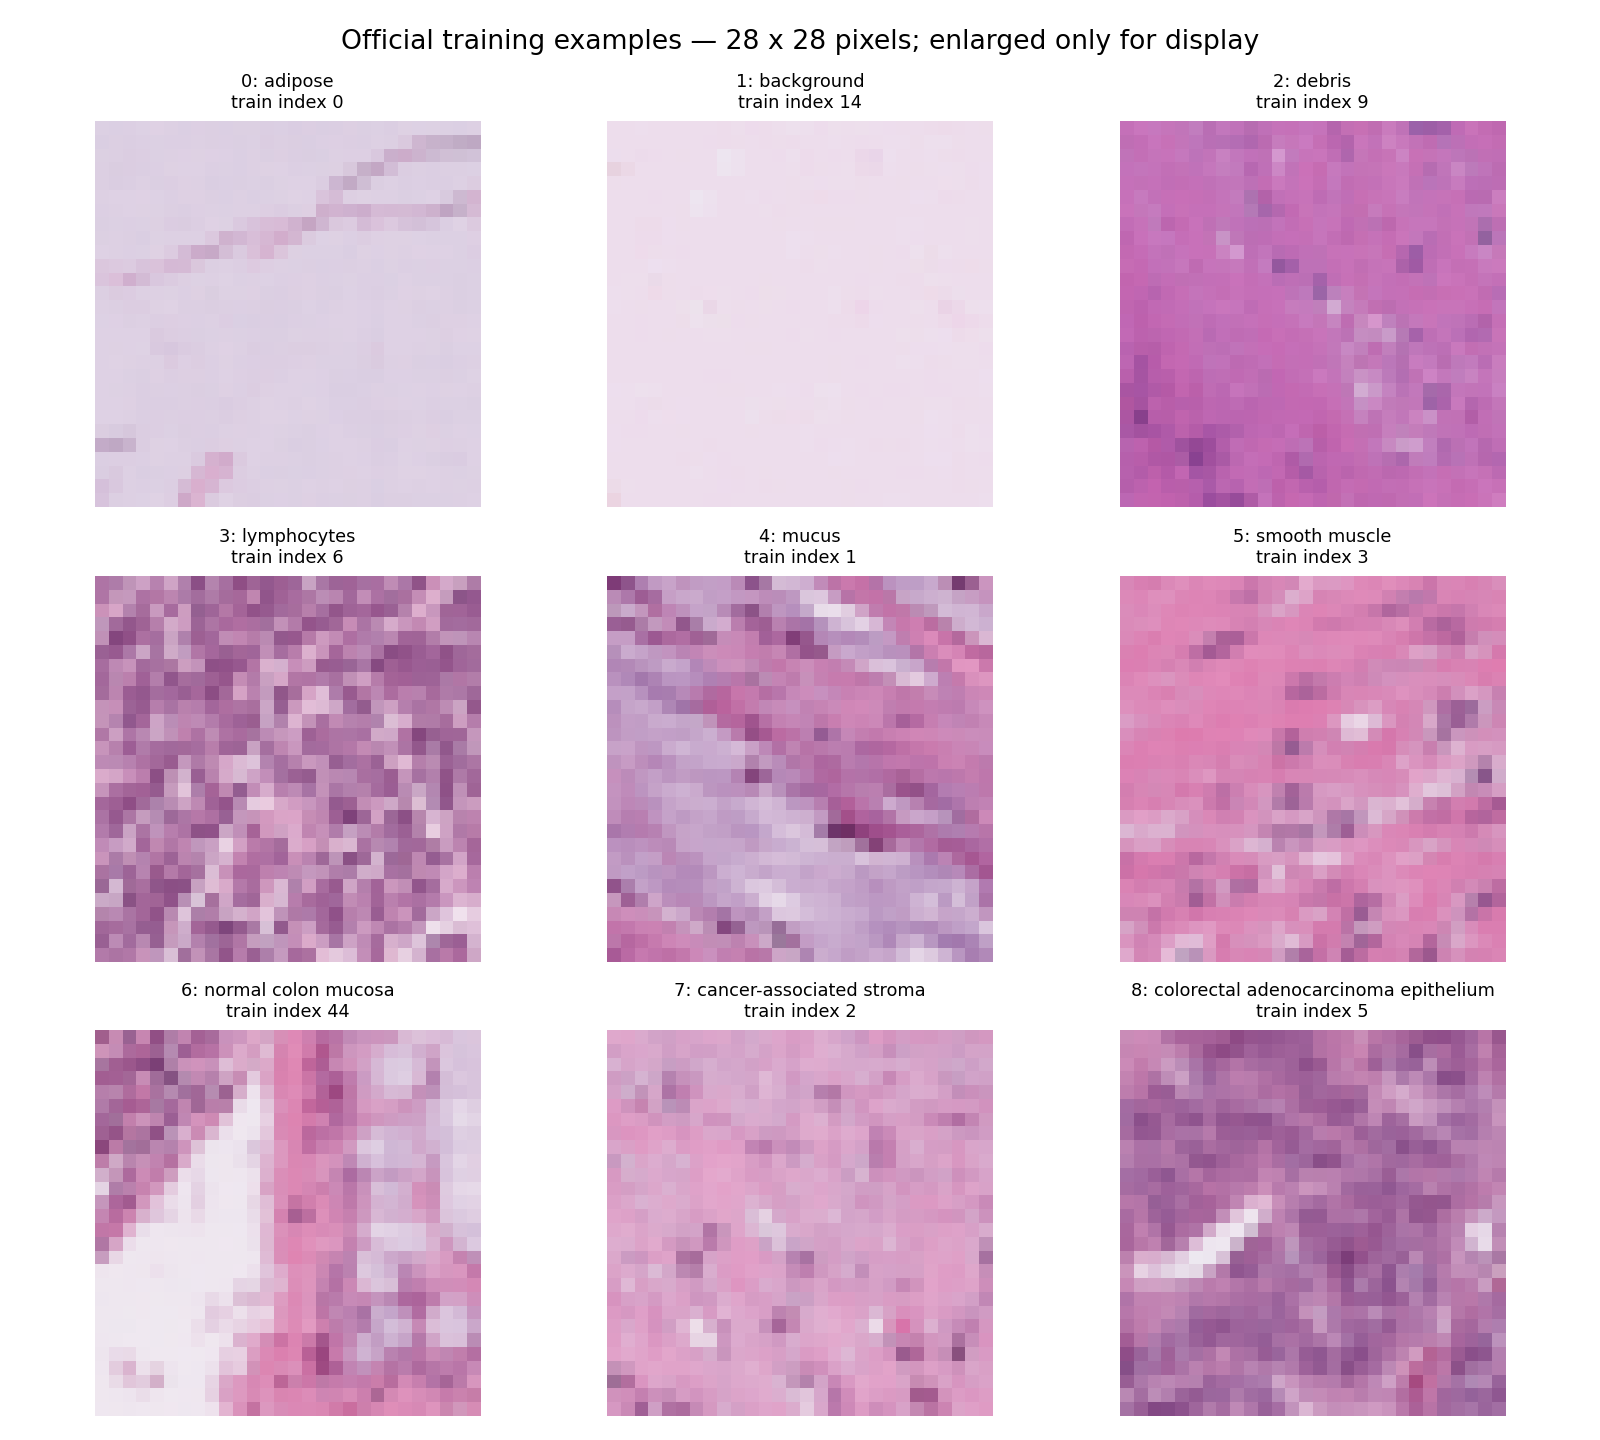

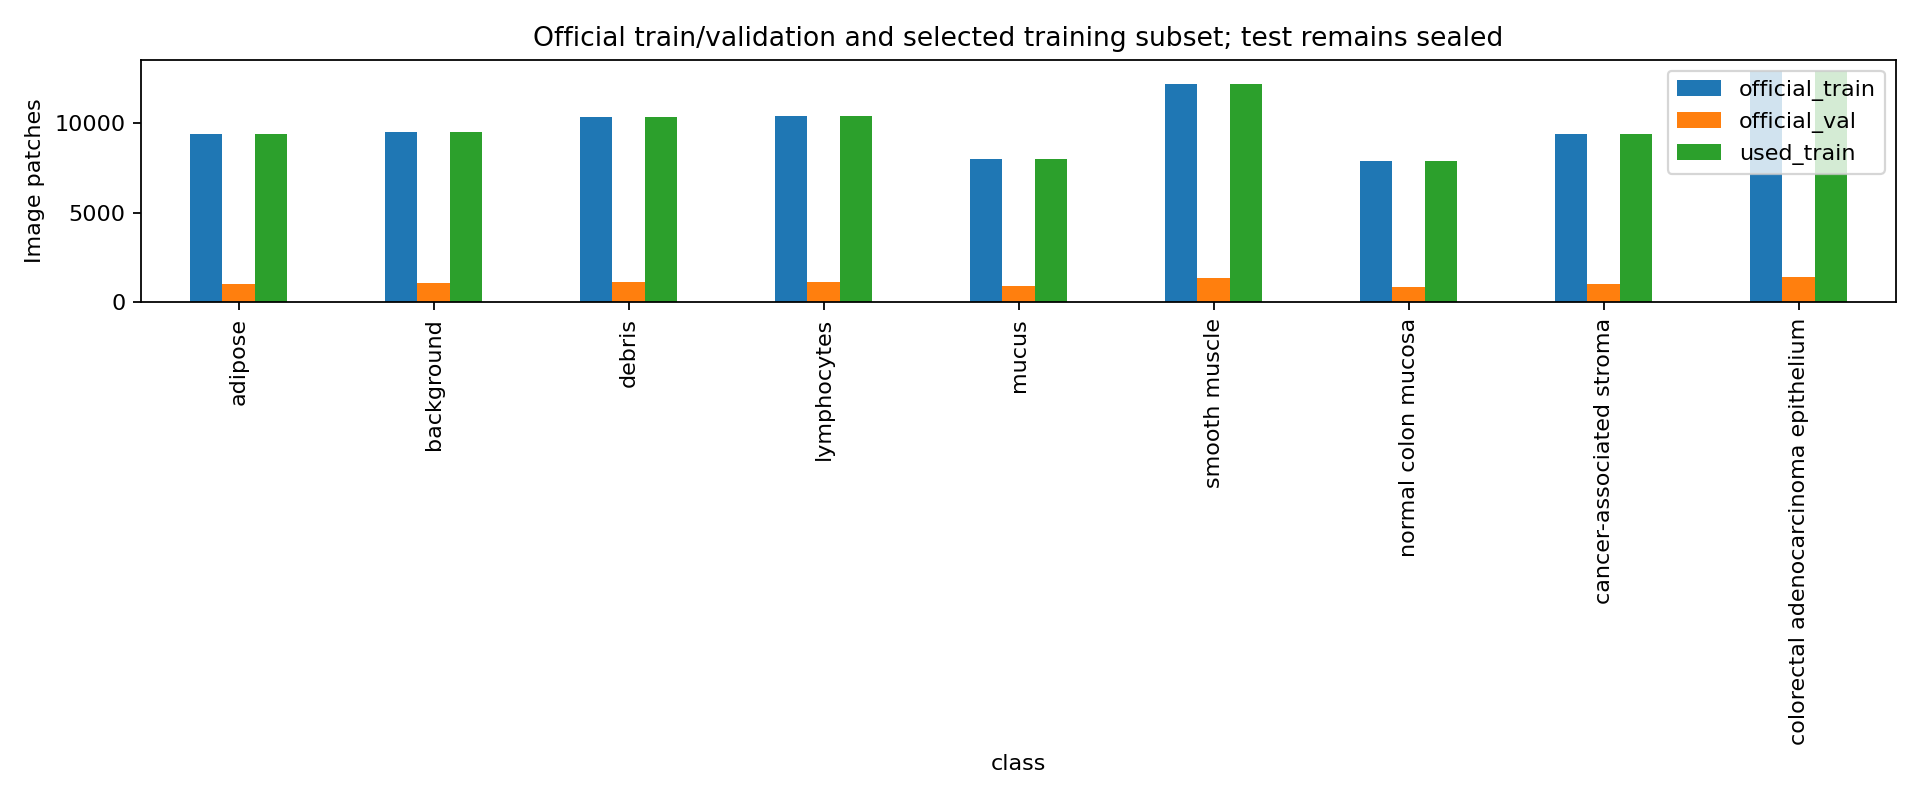

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 160MB/s]


{'cnn': {'input_shape': [2, 3, 28, 28], 'output_shape': [2, 9], 'labels_shape': [2], 'pretrained': False}, 'resnet18': {'input_shape': [2, 3, 224, 224], 'output_shape': [2, 9], 'labels_shape': [2], 'pretrained': True}}


In [4]:
display(experiment.prepare())
display(Image(filename=str(RUN_DIR/'exploration/labeled_training_examples.png')))
display(Image(filename=str(RUN_DIR/'exploration/class_counts.png')))
print(experiment.preflight())


## Cell 5 — Compact CNN baseline
Three convolution blocks learn local patterns: 3→32→64→128 channels, each with batch normalization, ReLU and max pooling. Global average pooling turns spatial maps into 128 features; dropout and a linear layer produce nine logits. The native 28×28 input is scaled to [0,1], then normalized with fixed mean/std 0.5. Cross-entropy consumes raw logits and integer labels.

AdamW learning rate 0.001, cosine schedule, weight decay 0.0001. Validation macro-F1 chooses the checkpoint; test images never enter training. Early stopping follows two non-improving validation epochs. CUDA uses mixed precision and gradient scaling.


{"epoch": 1, "train_loss": 0.5462522998036923, "val_loss": 0.4449265831377639, "train_accuracy": 0.8070692030756923, "val_accuracy": 0.8358656537385046, "val_macro_f1": 0.8308476812821625, "learning_rate": 0.001, "epoch_seconds": 38.95812251200002}
{"epoch": 2, "train_loss": 0.31700992590851546, "val_loss": 0.295557410656953, "train_accuracy": 0.8890839592870794, "val_accuracy": 0.8921431427429029, "val_macro_f1": 0.8931755057573967, "learning_rate": 0.0009619397662556434, "epoch_seconds": 37.13177503}
{"epoch": 3, "train_loss": 0.25002902426440543, "val_loss": 0.32452203699799836, "train_accuracy": 0.9127627894573093, "val_accuracy": 0.8884446221511395, "val_macro_f1": 0.887602529435283, "learning_rate": 0.0008535533905932738, "epoch_seconds": 38.06667660300002}
{"epoch": 4, "train_loss": 0.2093165273026385, "val_loss": 0.21924554124945214, "train_accuracy": 0.9282634783768168, "val_accuracy": 0.9271291483406637, "val_macro_f1": 0.9256272487811993, "learning_rate": 0.00069134171618254

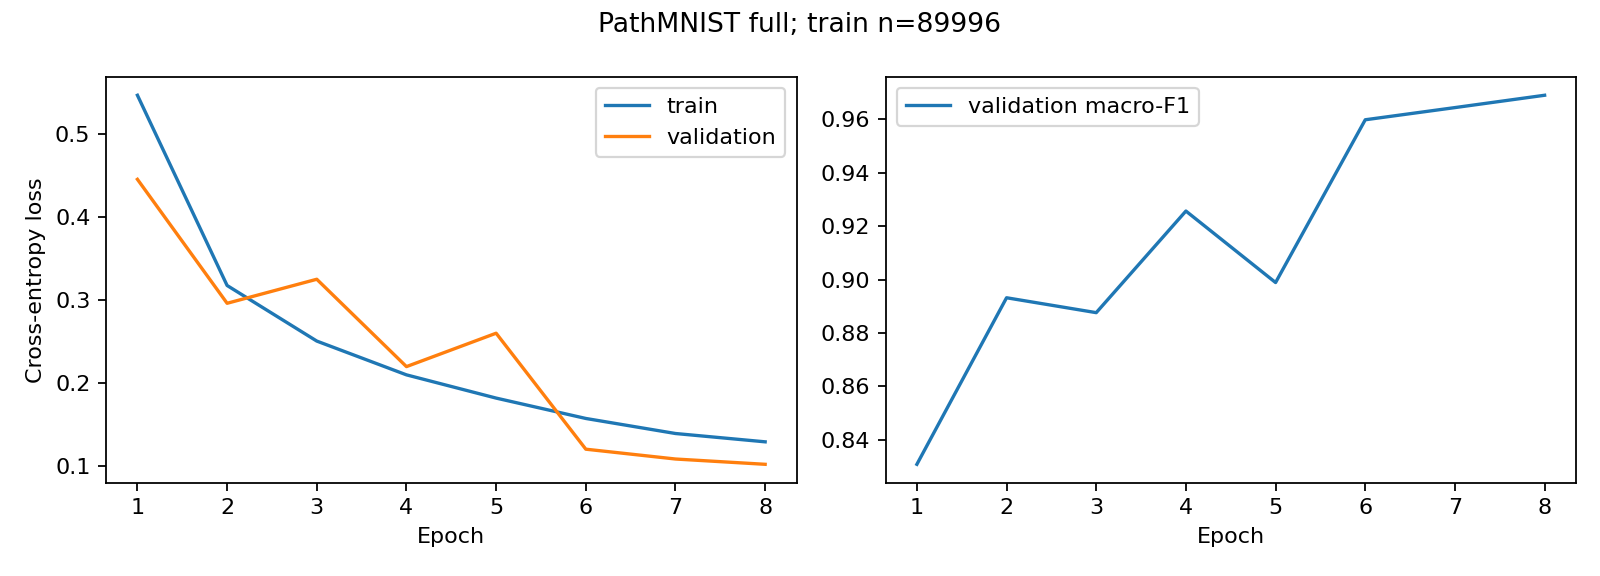

In [5]:
cnn_summary = experiment.train_one('cnn')
print(cnn_summary)
display(Image(filename=str(RUN_DIR/'cnn/learning_curves.png')))


## Cell 6 — Pretrained ResNet18 comparison
ImageNet pretraining supplies initial weights; its benefit here must be measured. ResNet shortcut connections add a block's input to its output. Replace the 512-to-1000 head with a 512-to-9 layer and train only the final residual stage (`layer4`) plus that head. Earlier layers and their batch-normalization running statistics stay frozen. AdamW LR is 0.0003.

We call `ResNet18_Weights.IMAGENET1K_V1.transforms()` exactly: bilinear resize to 256, center crop 224, scale to [0,1], normalize using ImageNet mean [0.485,0.456,0.406] and std [0.229,0.224,0.225]. Only training gets random flips beforehand. **Upsampling 28→224 does not restore microscopic detail**, and cropping discards some borders. Keeping the official preset makes the assumption explicit. A future MedMNIST+ experiment can test genuine higher-resolution input.


{"epoch": 1, "train_loss": 0.2603179311120747, "val_loss": 0.19280116476330075, "train_accuracy": 0.9095515356238055, "val_accuracy": 0.9319272291083567, "val_macro_f1": 0.9321083090566243, "learning_rate": 0.0003, "epoch_seconds": 341.012371061}
{"epoch": 2, "train_loss": 0.15968636963027197, "val_loss": 0.13448999540918305, "train_accuracy": 0.9439975110004889, "val_accuracy": 0.9514194322271091, "val_macro_f1": 0.9522377908097598, "learning_rate": 0.0002799038105676658, "epoch_seconds": 333.23999927599993}
{"epoch": 3, "train_loss": 0.11935697127762962, "val_loss": 0.1261669084882555, "train_accuracy": 0.9584870438686164, "val_accuracy": 0.9572171131547381, "val_macro_f1": 0.9576275984913811, "learning_rate": 0.000225, "epoch_seconds": 346.1495334419999}
{"epoch": 4, "train_loss": 0.09079834674789067, "val_loss": 0.10034112117049553, "train_accuracy": 0.9679874661096048, "val_accuracy": 0.9654138344662135, "val_macro_f1": 0.9654981815056356, "learning_rate": 0.00015, "epoch_seconds"

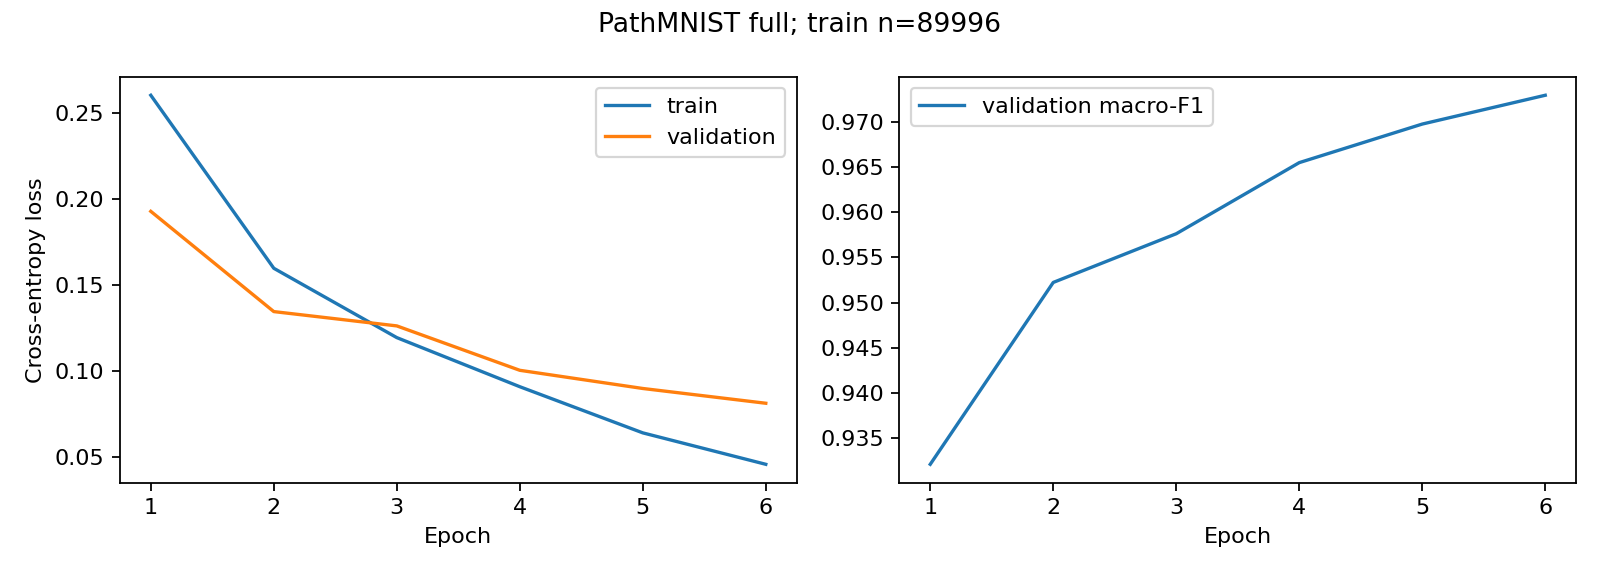

In [6]:
resnet_summary = experiment.train_one('resnet18')
print(resnet_summary)
display(Image(filename=str(RUN_DIR/'resnet18/learning_curves.png')))


## Cell 7 — Freeze selection before testing
Each model's best checkpoint uses validation macro-F1 (ties keep earlier epoch). Choose the overall model using validation macro-F1 only (model ties choose CNN). Save those choices and checkpoint hashes. Both fixed models will be reported on test, but do not switch the selection based on test performance.


In [7]:
selection = experiment.freeze_selection()
print(selection)


{'criterion': 'highest validation macro-F1; ties choose CNN', 'winner': 'resnet18', 'models': {'cnn': {'best_epoch': 8, 'best_val_macro_f1': 0.9689630384084258, 'epochs_completed': 8, 'epochs_budget': 8, 'training_seconds': 300.642103865, 'checkpoint_sha256': '22270e10b830c26382b394ce34cb99947268111efecca9db8fbc02f89b878932', 'parameters': 94633, 'trainable_parameters': 94633}, 'resnet18': {'best_epoch': 6, 'best_val_macro_f1': 0.9729559582969842, 'epochs_completed': 6, 'epochs_budget': 6, 'training_seconds': 2036.080073816, 'checkpoint_sha256': 'e21f2b2eb3d3044e3f524c2d55aeb199598eff5d75e6a0301c7d86bfb08916eb', 'parameters': 11181129, 'trainable_parameters': 8398345}}, 'frozen_before_test': True, 'frozen_utc': '2026-10-20T18:13:58.774894+00:00'}


## Cell 8 — Final official test evaluation and actual comparison
This is the first stage that analyzes official test images/labels. Accuracy is the fraction correct. Precision asks how often predictions of a class are correct; recall asks how much of the true class was found; F1 balances both. Macro-F1 averages nine class F1 scores equally. Undefined precision/recall is reported as zero, and support shows the denominator.

The confusion matrix uses true classes as rows and predictions as columns. Class-normalized rows help compare different class sizes. Correct/incorrect grids show the first examples in split order, with indices traceable to the saved probabilities. Maximum softmax values are not calibrated clinical confidence. Tables are generated only from this run's measured predictions.


,model,train_n,test_n,best_epoch,best_val_macro_f1,test_accuracy,test_macro_f1,training_seconds,selected_by_validation
0,cnn,89996,7180,8,0.968963,0.894986,0.857976,300.642104,False
1,resnet18,89996,7180,6,0.972956,0.913231,0.885539,2036.080074,True


,class,official_train,official_val,used_train,official_test_final_only
0,adipose,9366,1041,9366,1338
1,background,9509,1057,9509,847
2,debris,10360,1152,10360,339
3,lymphocytes,10401,1156,10401,634
4,mucus,8006,890,8006,1035
5,smooth muscle,12182,1354,12182,592
6,normal colon mucosa,7886,877,7886,741
7,cancer-associated stroma,9401,1045,9401,421
8,colorectal adenocarcinoma epithelium,12885,1432,12885,1233


### cnn

,precision,recall,f1-score,support
adipose,0.910153,0.931241,0.920576,1338.000000
background,0.965792,1.000000,0.982599,847.000000
debris,0.595388,0.837758,0.696078,339.000000
lymphocytes,0.946237,0.971609,0.958755,634.000000
mucus,0.973306,0.915942,0.943753,1035.000000
smooth muscle,0.731707,0.760135,0.745650,592.000000
normal colon mucosa,0.956012,0.879892,0.916374,741.000000
cancer-associated stroma,0.761246,0.522565,0.619718,421.000000
colorectal adenocarcinoma epithelium,0.933387,0.943228,0.938282,1233.000000
accuracy,0.894986,0.894986,0.894986,0.894986


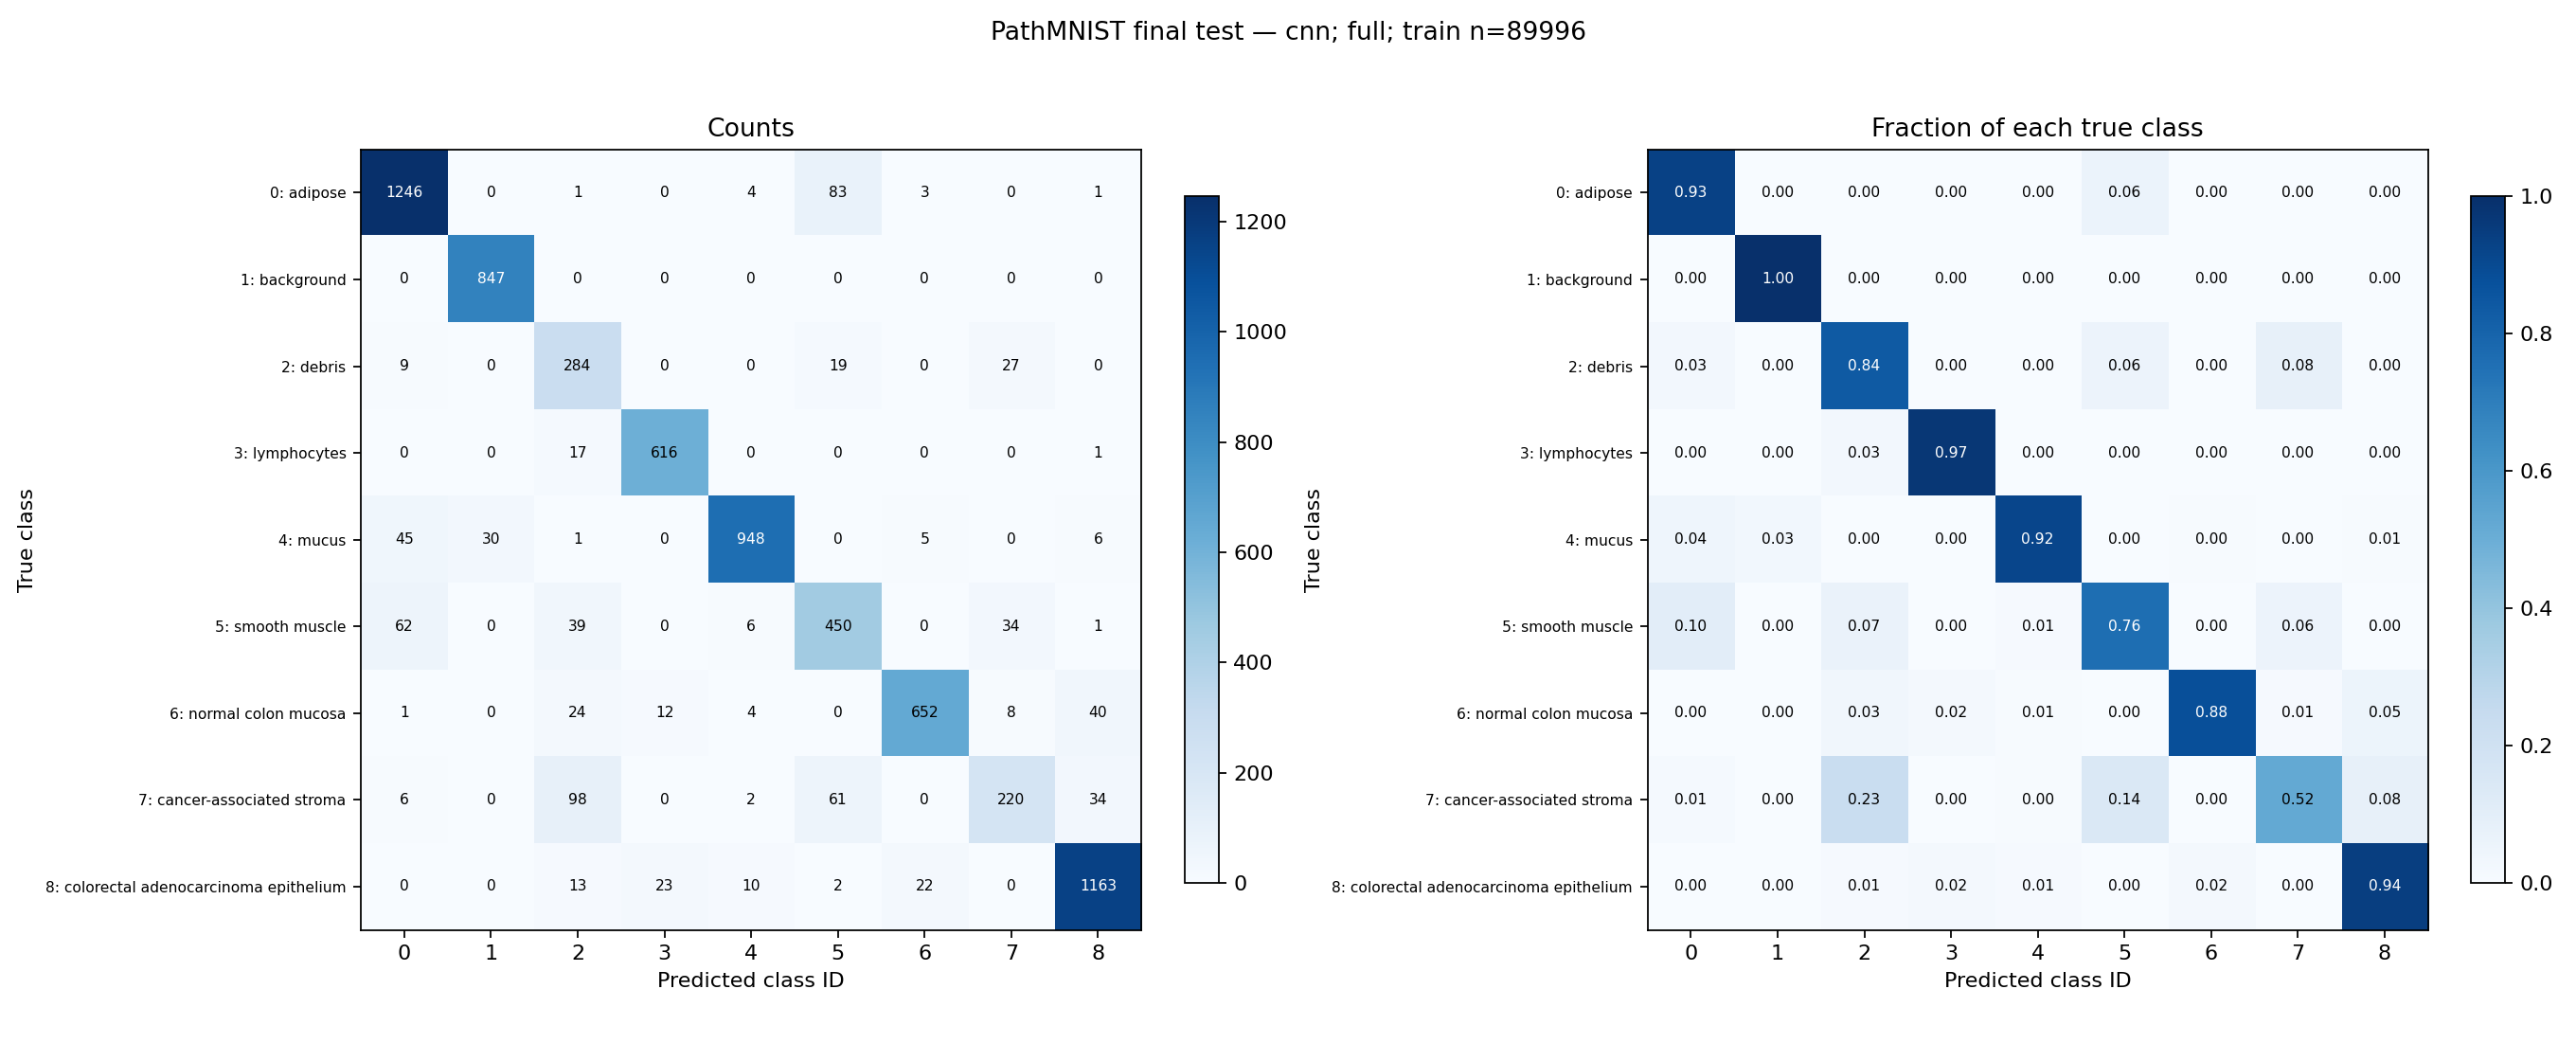

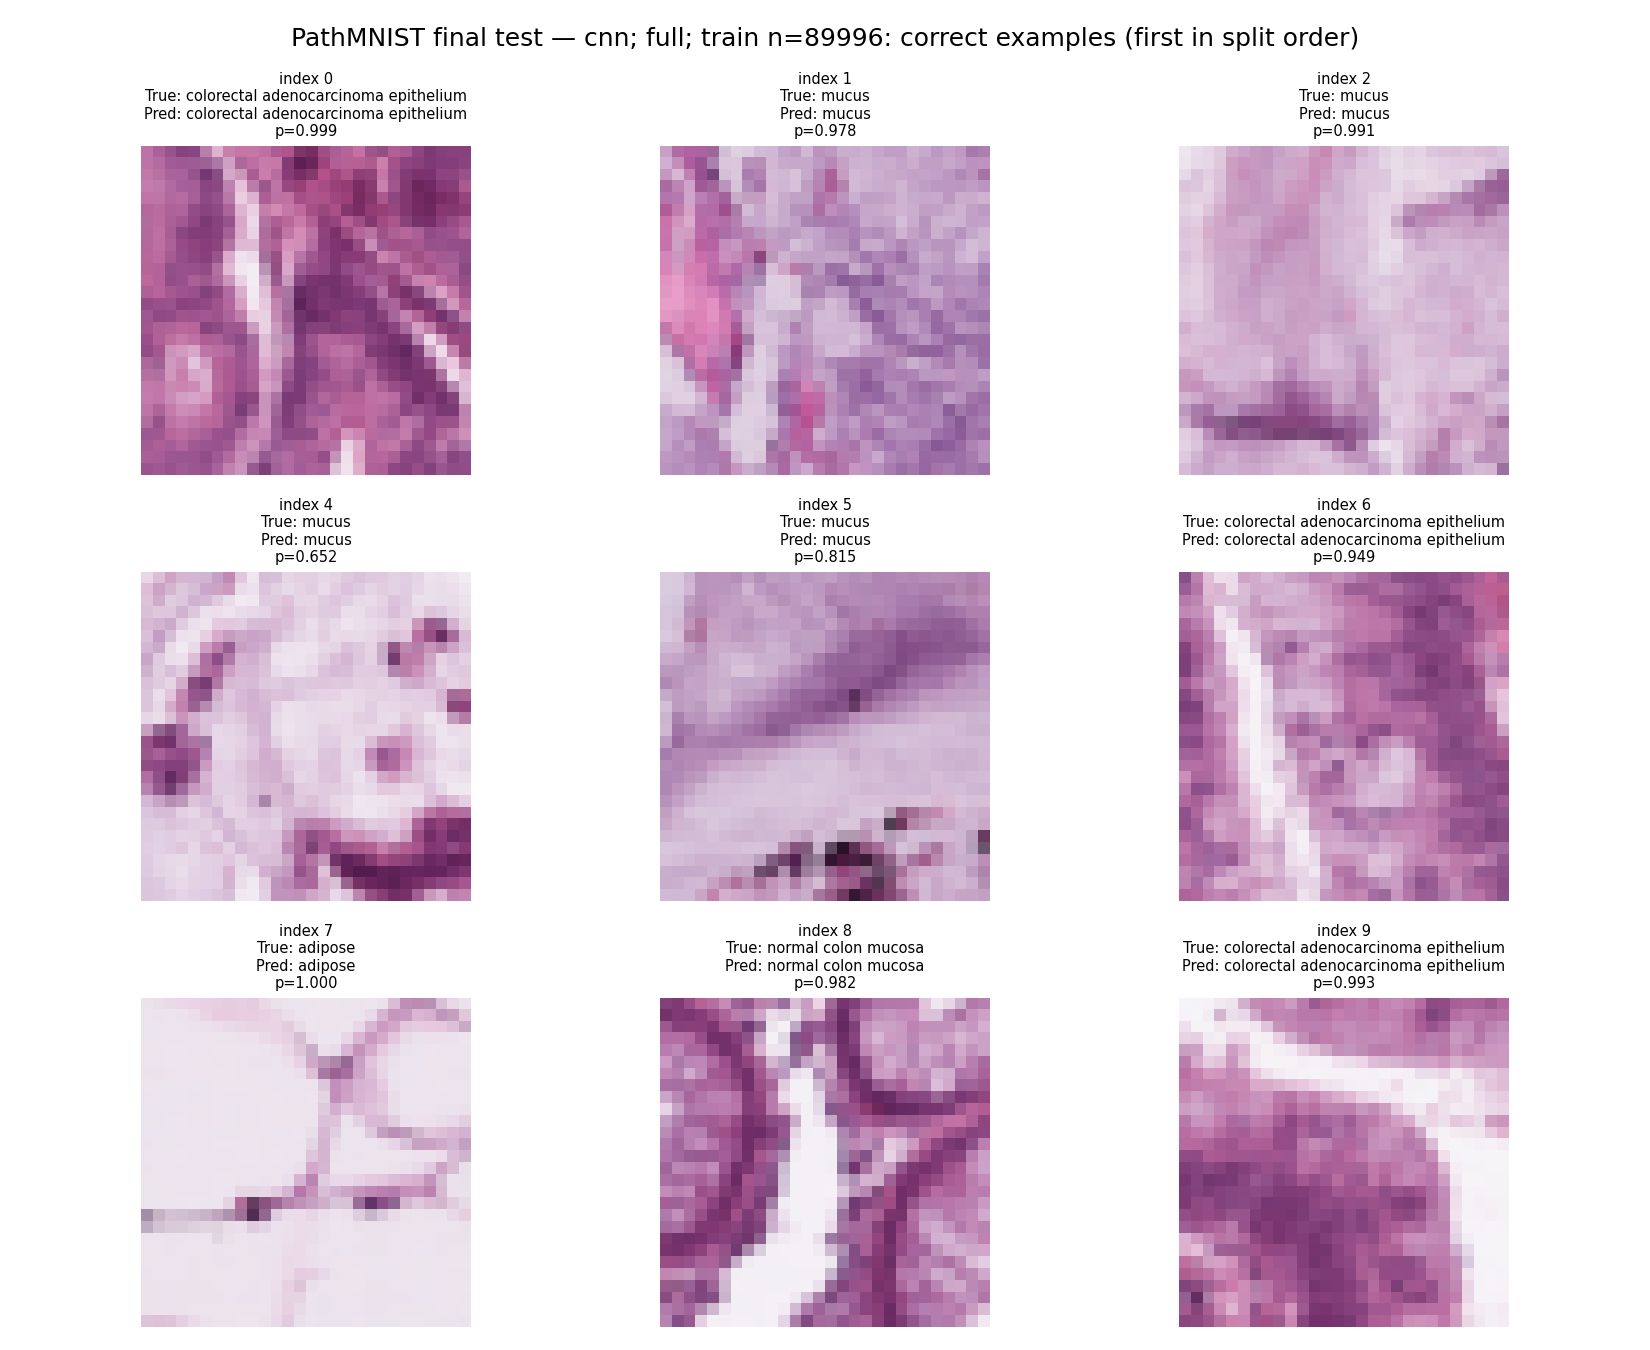

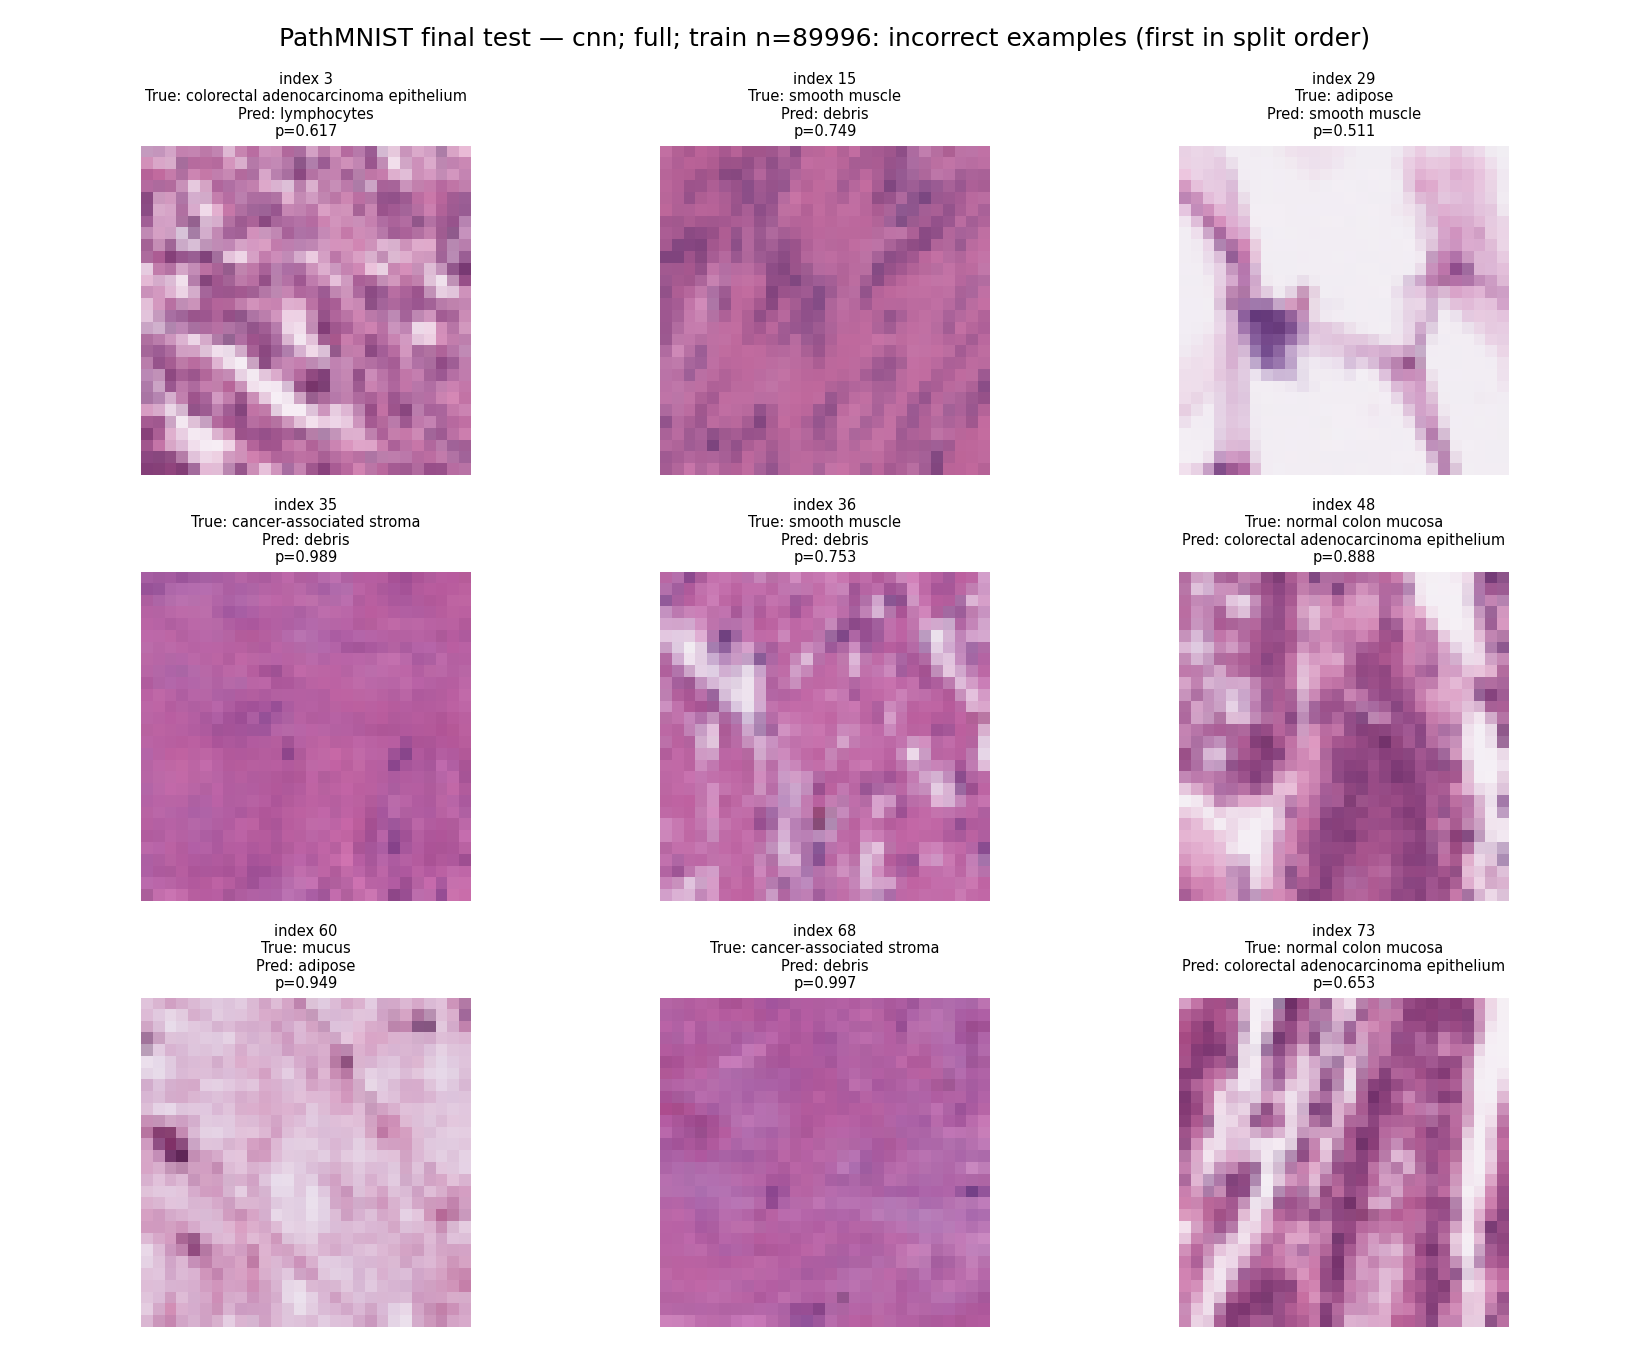

# Error analysis — PathMNIST final test — cnn; full; train n=89996

Measured directed confusions (ranked by count):

- cancer-associated stroma → debris: 98 images; 23.3% of the true class.
- adipose → smooth muscle: 83 images; 6.2% of the true class.
- smooth muscle → adipose: 62 images; 10.5% of the true class.
- cancer-associated stroma → smooth muscle: 61 images; 14.5% of the true class.
- mucus → adipose: 45 images; 4.3% of the true class.

These counts show where predictions failed, not why. Inspect the saved example images and original labels.
Possible explanations such as downsampling, similar color/texture, or mixed tissue require visual review and higher-resolution evidence.
No claim about a biological mechanism, immune response, prognosis, or patient diagnosis follows from this table.
See docs/error_analysis.md for the observation-versus-hypothesis worksheet.


### resnet18

,precision,recall,f1-score,support
adipose,0.981775,0.926009,0.953077,1338.000000
background,0.905882,1.000000,0.950617,847.000000
debris,0.786432,0.923304,0.849389,339.000000
lymphocytes,0.933036,0.988959,0.960184,634.000000
mucus,0.984756,0.936232,0.959881,1035.000000
smooth muscle,0.749591,0.773649,0.761430,592.000000
normal colon mucosa,0.939189,0.937922,0.938555,741.000000
cancer-associated stroma,0.747748,0.591449,0.660477,421.000000
colorectal adenocarcinoma epithelium,0.931727,0.940795,0.936239,1233.000000
accuracy,0.913231,0.913231,0.913231,0.913231


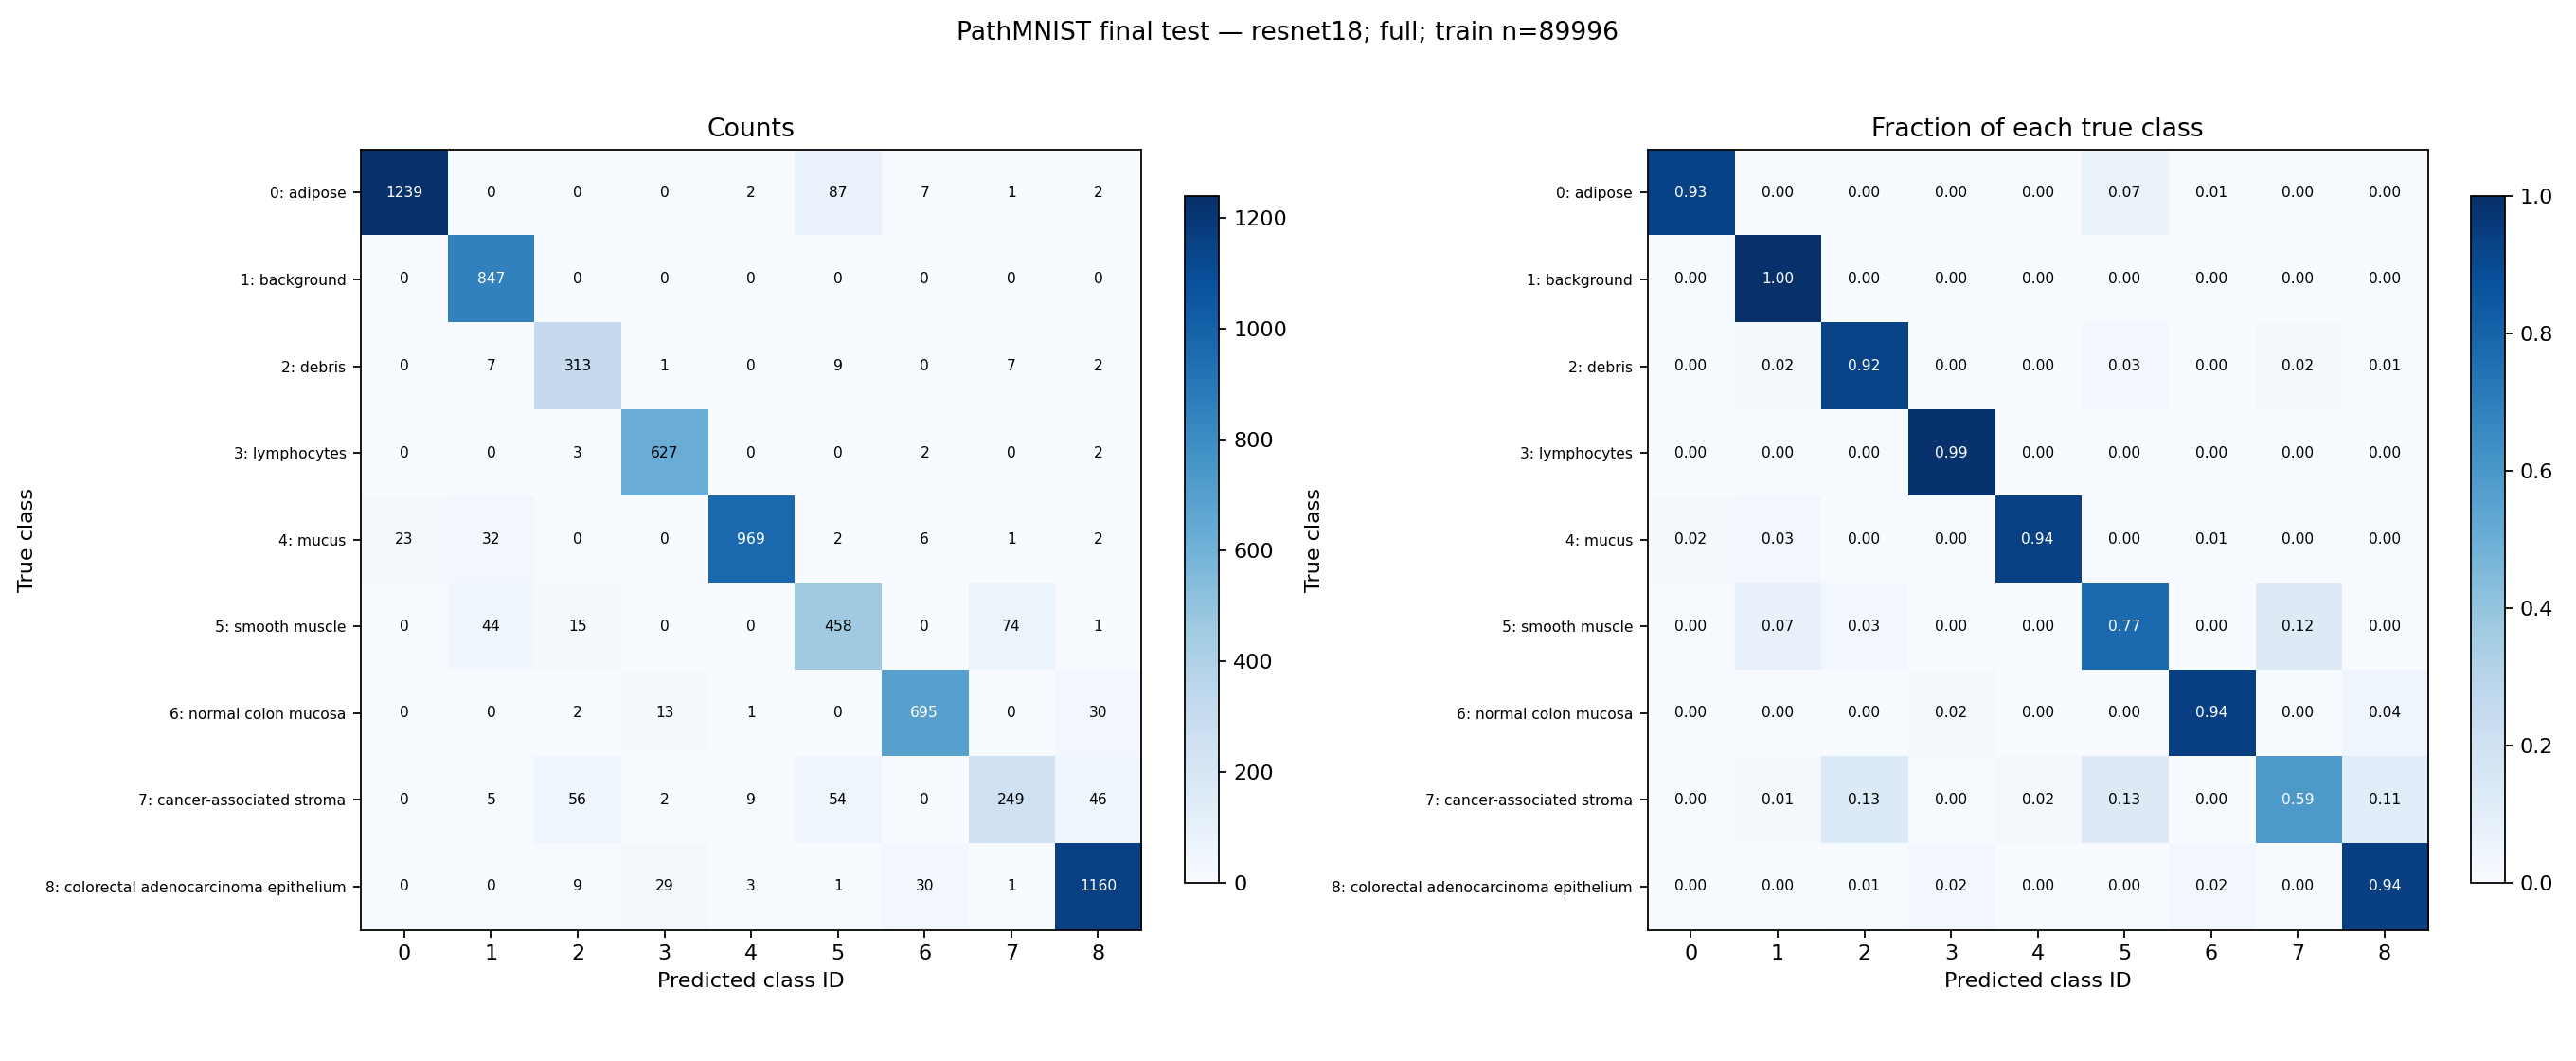

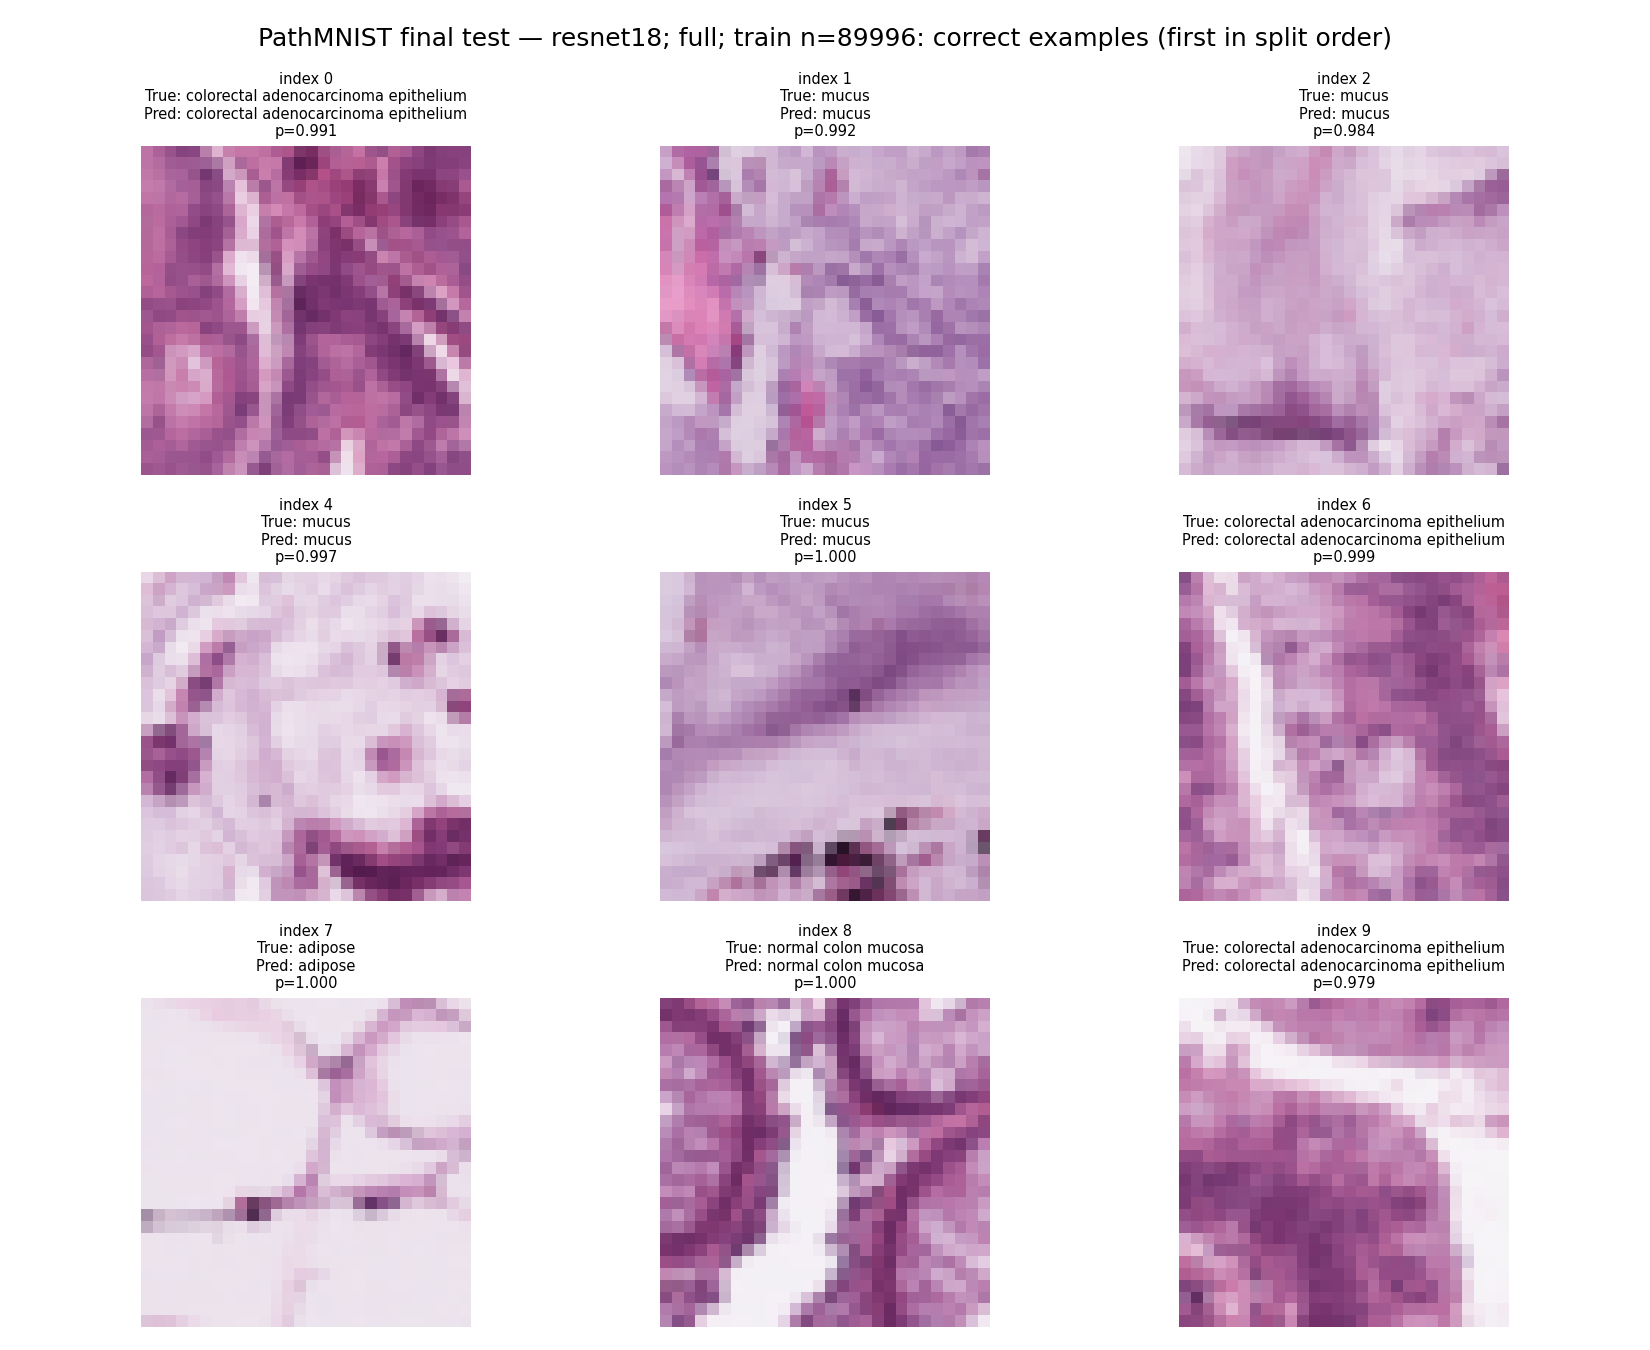

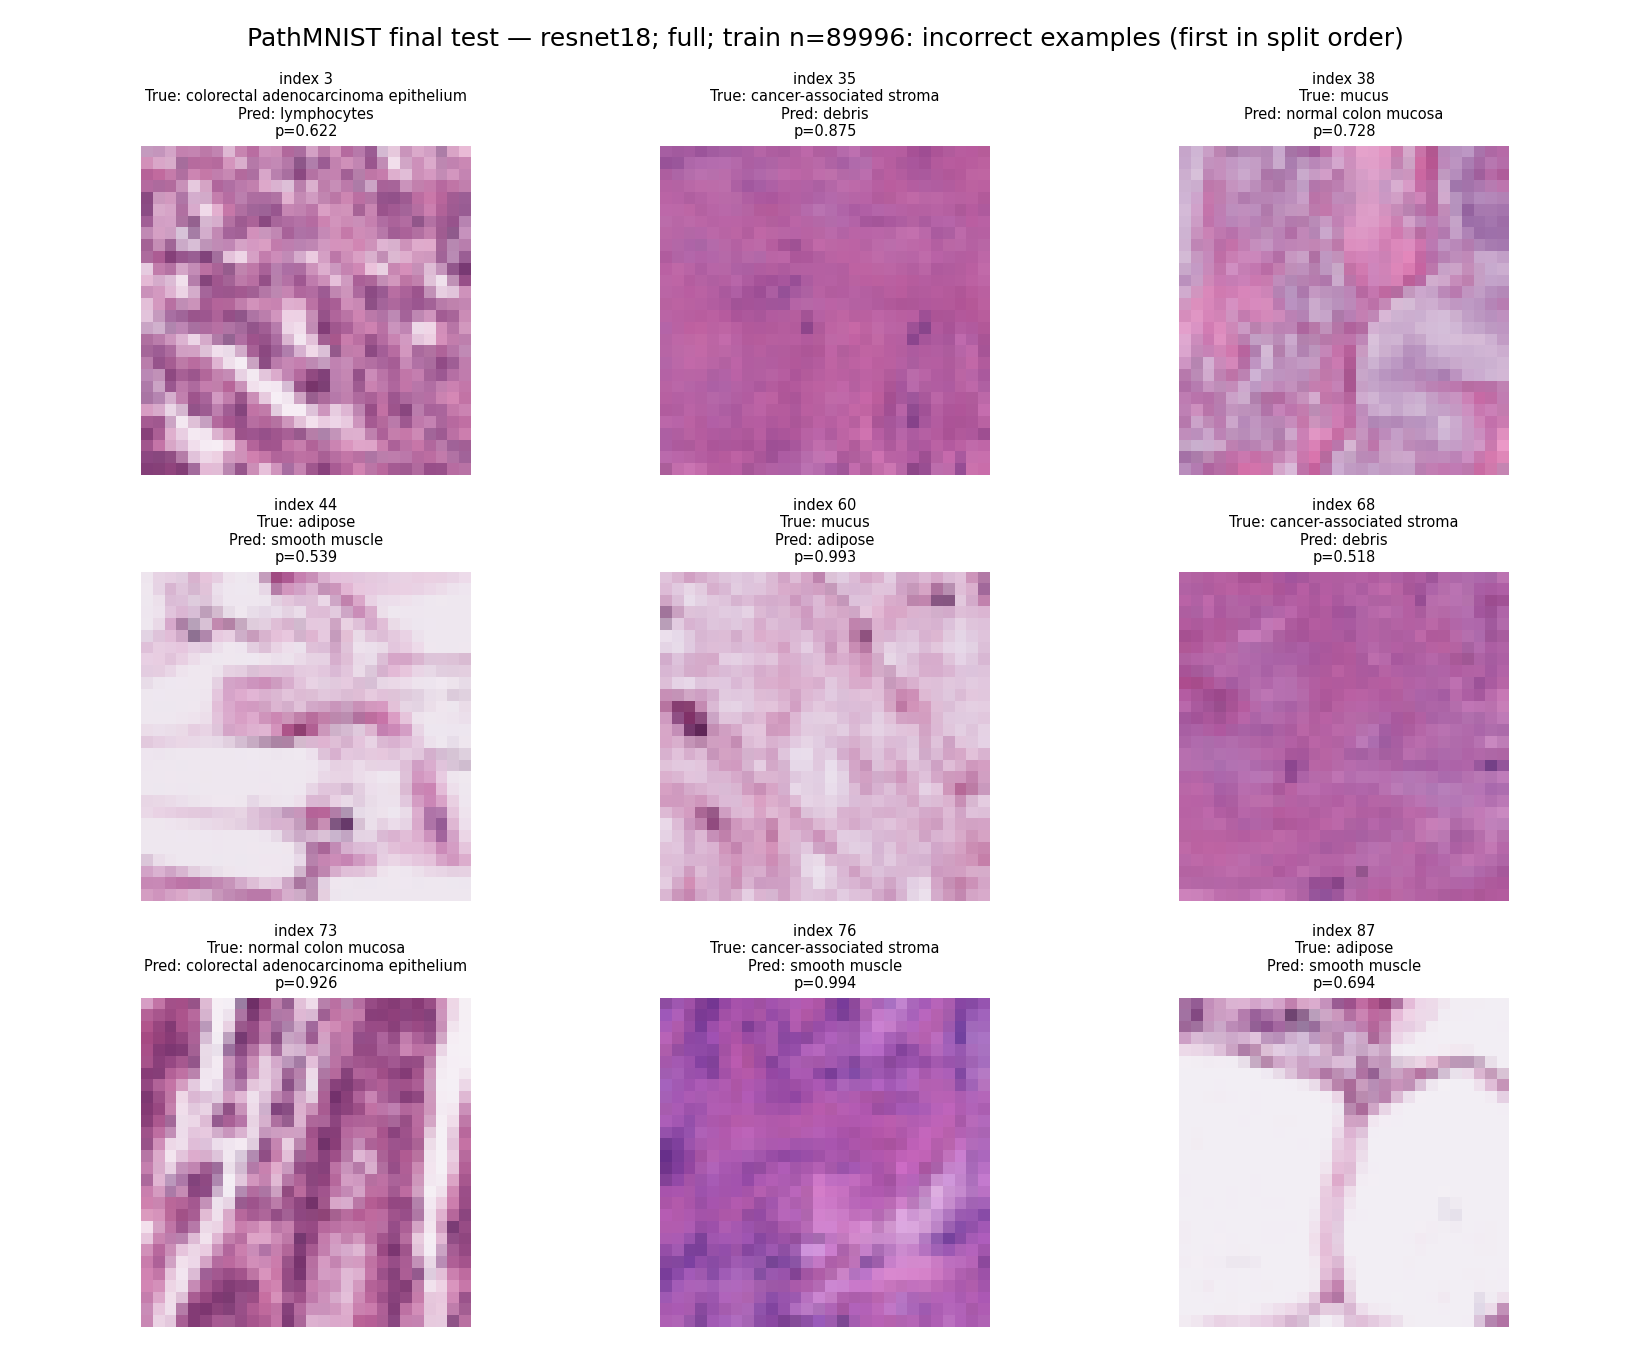

# Error analysis — PathMNIST final test — resnet18; full; train n=89996

Measured directed confusions (ranked by count):

- adipose → smooth muscle: 87 images; 6.5% of the true class.
- smooth muscle → cancer-associated stroma: 74 images; 12.5% of the true class.
- cancer-associated stroma → debris: 56 images; 13.3% of the true class.
- cancer-associated stroma → smooth muscle: 54 images; 12.8% of the true class.
- cancer-associated stroma → colorectal adenocarcinoma epithelium: 46 images; 10.9% of the true class.

These counts show where predictions failed, not why. Inspect the saved example images and original labels.
Possible explanations such as downsampling, similar color/texture, or mixed tissue require visual review and higher-resolution evidence.
No claim about a biological mechanism, immune response, prognosis, or patient diagnosis follows from this table.
See docs/error_analysis.md for the observation-versus-hypothesis worksheet.


# Measured PathMNIST results

Generated from saved predictions after validation-only checkpoint selection.

| Model | Train n | Test n | Accuracy | Macro-F1 | Best epoch |
|---|---:|---:|---:|---:|---:|
| cnn | 89996 | 7180 | 0.8950 | 0.8580 | 8 |
| resnet18 | 89996 | 7180 | 0.9132 | 0.8855 | 6 |

Validation-selected model: resnet18. Both prespecified models are reported; do not pick a winner using test scores.
Single-seed patch-level experiment. This is not clinical validation. Do not tune on these test errors.


In [8]:
import pandas as pd
comparison = experiment.evaluate_final()
display(comparison[['model','train_n','test_n','best_epoch','best_val_macro_f1',
                    'test_accuracy','test_macro_f1','training_seconds','selected_by_validation']])
display(pd.read_csv(RUN_DIR/'exploration/class_counts_all_splits.csv'))
for name in ['cnn','resnet18']:
    report_dir = RUN_DIR/name/'final_test'
    display(Markdown('### ' + name))
    display(pd.read_csv(report_dir/'classification_report.csv', index_col=0))
    display(Image(filename=str(report_dir/'confusion_matrix.png')))
    display(Image(filename=str(report_dir/'correct_examples.png')))
    display(Image(filename=str(report_dir/'incorrect_examples.png')))
    display(Markdown((report_dir/'error_analysis.md').read_text()))
display(Markdown((RUN_DIR/'RESULTS.md').read_text()))


## Cell 9 — Error review, interview preparation and limits
The generated error report states measured confusions. Biological causes require expert review and additional evidence. Open the worksheet below, then inspect the top directed pairs and indexed examples. Distinguish “the model confused A with B” from an unverified explanation for why. Do not tune this experiment after seeing test errors.

Limitations: reduced resolution, correlated patches, one seed, unverified patient-level train/validation separation, no clinical validation, no calibration or scanner/stain robustness study. This does not measure prognosis, immune activity or treatment response. The embedded interview guide explains implementation, tensors, a sample data flow, design alternatives and eight follow-up questions. Its execution-status sentence must be updated truthfully after your completed run; resume bullets intentionally omit unmeasured performance.


In [ ]:
display(Markdown((PROJECT/'docs/error_analysis.md').read_text()))
for name in ['cnn','resnet18']:
    print(name, 'largest measured directed confusions:')
    display(pd.read_csv(RUN_DIR/name/'final_test/confusion_pairs.csv').head(5))
print('Interview guide:', PROJECT/'docs/interview_guide.md')
print('Resume bullets:', PROJECT/'docs/resume_bullets.md')


## Cell 10 — Save the completed experiment
Downloads code, documentation, plots, predictions, metrics and best checkpoints. Raw data and cached ImageNet weights are excluded because the notebook downloads official copies. Download the executed notebook separately so your visible outputs are retained. Checkpoints support inference; exact interrupted-training resume is not implemented.


In [10]:
import zipfile
archive = PROJECT/(run_id + '_results.zip')
with zipfile.ZipFile(archive, 'w', zipfile.ZIP_DEFLATED) as z:
    for folder in ['histology','docs','tests']:
        for path in (PROJECT/folder).rglob('*'):
            if path.is_file() and '__pycache__' not in path.parts:
                z.write(path, path.relative_to(PROJECT).as_posix())
    for name in ['README.md','EXECUTION_STATUS.md','requirements.txt','run_experiment.py']:
        z.write(PROJECT/name, name)
    for path in RUN_DIR.rglob('*'):
        if path.is_file():
            z.write(path, 'outputs/'+run_id+'/'+path.relative_to(RUN_DIR).as_posix())
print('Saved:', archive, 'bytes:', archive.stat().st_size)
try:
    from google.colab import files
    files.download(str(archive))
except ImportError:
    print('Outside Colab: open the ZIP at the path printed above.')


Saved: /content/colorectal_histology/full_20261020T173424850797Z_results.zip bytes: 43804174


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Verified sources and attribution

Checked 2026-10-20. Primary sources were read for metadata, licensing, API behavior and preprocessing.

1. MedMNIST official site: https://medmnist.com/ — educational benchmark, standardized splits, license, clinical-use disclaimer.
2. Official metadata: https://github.com/MedMNIST/MedMNIST/blob/main/medmnist/info.py — PathMNIST label order; train 89996, val 10004, test 7180; version 3.0.2; CC BY 4.0; archive URL/checksum.
3. Official API README: https://github.com/MedMNIST/MedMNIST — `PathMNIST`, `split`, `size`, `download=True`; six arrays; Zenodo official distribution.
4. Official PathMNIST archive: https://zenodo.org/records/10519652/files/pathmnist.npz?download=1 — accessed automatically through the package. Expected MD5 from metadata: `a8b06965200029087d5bd730944a56c1`.
5. Original data: Kather, Halama, Marx, “100,000 histological images of human colorectal cancer and healthy tissue”: https://zenodo.org/records/1214456 — original patch construction, color normalization, tissue categories and separate 7K cohort. Source archive describes 50 patients in the 7K cohort with no overlap with the 100K cohort. This is a source-reported property, not this project's independent patient-ID audit.
6. MedMNIST v2 paper: Yang et al., Scientific Data (2023), https://doi.org/10.1038/s41597-022-01721-8; author manuscript https://arxiv.org/abs/2110.14795 . MedMNIST's requested citation. The publisher page was not accessible in this session; project metadata and official repository were used for implementation facts.
7. Kather et al., “Predicting survival from colorectal cancer histology slides using deep learning: A retrospective multicenter study,” PLOS Medicine (2019), https://doi.org/10.1371/journal.pmed.1002730 — original study attribution. This portfolio task does not reproduce survival prediction.
8. torchvision ResNet18: https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html — `IMAGENET1K_V1`, bilinear resize to 256, center crop 224, mean [0.485,0.456,0.406], std [0.229,0.224,0.225]. The code calls the preset instead of reimplementing it.
9. National Cancer Institute H&E definition: https://www.cancer.gov/publications/dictionaries/cancer-terms/def/hematoxylin-and-eosin-staining — plain-language stain explanation.
10. CC BY 4.0: https://creativecommons.org/licenses/by/4.0/ . Credit the creators, link the license, and identify changes. MedMNIST upstream code: https://github.com/MedMNIST/MedMNIST/blob/main/LICENSE .

Suggested data attribution on exported figures: “PathMNIST / MedMNIST (Yang et al.), derived from NCT-CRC-HE-100K and CRC-VAL-HE-7K (Kather et al.), CC BY 4.0. Images downsampled by MedMNIST; visualization/preprocessing as documented in this project.”

No dataset or pretrained weight redistribution is included. The downloaded archive's hash and package metadata are saved by each run. License facts are reproduced from the upstream documentation, not a claim of legal review.
